# Helsinki region: a decent-mobility week per postal code, in time, money and CO₂, by mode

What does a week of decent mobility cost a resident of each postal code in minutes,
euros and kg CO₂e, by public transport, car, bicycle and e-bike, and where does each mode
hold an advantage?

The notebook combines two earlier pieces. Notebook `02.5` gives, for every app user
and destination category, the cost of the round trip from home at which a given
share of the user's visits is reached, per mode, in time, distance and CO₂. The
carbon-budget paper (`05_carbon_cost_of_decent_mobility/tours`) defines a weekly
decent-mobility routine of tours per category. Multiplying the two gives a weekly
cost per resident, mode and currency, which is then summarised per postal code and
compared across modes.

Money follows the conventions of notebook `02.4`: the car at a running cost per
driven kilometre, the bicycle at the bicycle running cost of `02.1`, the e-bike at 1.7 times that rate, and public transport at
the HSL single ticket of the zone pair, priced exactly by the `02.1` transit matrix.
Car, bicycle and e-bike money are linear in distance, so their money curves are the `02.5`
distance curves times the rate. Transit fares are a step function of zones, so the
notebook prices every home-to-stay pair on the `02.1` lattice and builds the money
curve per user the way `02.5` builds the others.

**Logic, in one paragraph.** For each resident and category, the near trip is the
round-trip cost at which `THRESHOLD` percent of the resident's visits to that
category are reached (the cheapest fifth of the activity space when the threshold
is 20 %). The decent week sums, over the categories of the routine, the number of
weekly tours times the near trip. Residents enter only if the near trip exists for
every category of the routine, every mode and every currency, so the four modes
are compared on the same people. Per postal code, the weekly cost per mode, the
difference and ratio of each alternative mode against the car, the share of
residents for whom the alternative costs less, and the extra minutes paid per kg
CO₂e avoided are summarised across residents. The same comparison is repeated per
category, without the weekly weights, to see where each mode competes.

**Inputs** (all pre-existing)

- `typical_trip_by_user.parquet` from notebook `02.5`: one row per user, category,
  mode and currency (time, distance, CO₂), with the cost at every decile of the
  user's visits and the user's home postal code.
- `users_and_stays_3months.parquet` and `pois_per_hex_new_class.parquet`: the stays
  and the POI counts per hexagon, as in `02.5`, used only to price transit fares.
- `transit/` from notebook `02.1`: the transit matrix on the H3 resolution 8 lattice,
  with the HSL single ticket per hexagon pair.
- `Postinumeroalueet_2024.shp`: the postal code areas of Helsinki, Espoo and Vantaa.

**Outputs** on scratch under `carbon-advantage/helsinki/decent-week/`

- `near_trip_by_user.parquet`: one row per resident, category, mode and currency
  with the near trip, including the money rows built here.
- `decent_week_by_user.parquet`: one row per resident and currency, with the weekly
  cost per mode and the difference and ratio of each alternative against the car.
- `price_of_carbon_by_user.parquet`: per resident, alternative mode and currency
  (time, money), the extra cost per week divided by the kg CO₂e saved against the car.
- `decent_week_by_postal_code.parquet`: one row per postal code, currency and
  metric, with the median, mean, quartiles and resident count;
  `decent_week_<currency>.csv` holds the medians in wide form.
- `share_below_reference_by_postal_code.parquet`: share of residents for whom the
  alternative mode costs less than the car, per currency.
- `price_of_carbon_by_postal_code.parquet`: summary of the price of carbon in time and money.
- `near_trip_by_postal_code_and_category.parquet`: per postal code and category,
  the near trip per mode and the log ratio of each alternative against the car.
- `parameters.json`: the settings below.

In [1]:
import json
from pathlib import Path

import geopandas as gpd
import h3
import matplotlib.patheffects as patheffects
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd

## Parameters

The weekly routine is the worker profile of the carbon-budget paper without the
commute: one shopping tour, two social or cultural tours and two recreation tours
per week. Healthcare and education carry no weekly tour in that routine; they stay
in the per-category comparison of section 5 and can be given a weight here.

The money rates are those of `02.4`: 0.36 EUR per driven kilometre for the car
(the 0.25 EUR2017 of `02.1` brought to current euros) and the bicycle's 0.047
EUR2017 per kilometre from `02.1`, left as `02.4` uses it. cafein prices the e-bike on the
bicycle cost row; here the e-bike is set at `EBIKE_COST_FACTOR` = 1.7 times the bicycle rate
(0.080 EUR per kilometre), a placeholder for the higher purchase, battery and electricity
costs until a sourced figure replaces it. Transit money is the
single ticket of the `02.1` matrix; a season-ticket lower bound is not computed.

In [2]:
PAPER = Path("/projappl/project_2010423/carbon_budgets_paper")
SCRATCH = Path("/scratch/project_2010423")
HELSINKI = SCRATCH / "carbon-advantage" / "helsinki"
VISITATION = HELSINKI / "visitation"
RESULTS = HELSINKI / "decent-week"
RESULTS.mkdir(parents=True, exist_ok=True)
POSTAL_CODES = PAPER / "data" / "postal_code" / "Postinumeroalueet_2024.shp"
STAYS = SCRATCH / "data" / "users_and_stays_3months.parquet"
POIS = PAPER / "data" / "pois_per_hex_new_class.parquet"
TRANSIT_MATRIX = HELSINKI / "transit"   # 02.1, H3 resolution 8 lattice, HSL single tickets

# Share of a resident's visits (percent) at which the round-trip cost is read.
THRESHOLD = 20

# Tours per week and category: the decent-mobility routine of the carbon-budget
# paper (05_carbon_cost_of_decent_mobility/tours), commute left out.
WEEKLY_VISITS = {
    "Shopping, Errands": 1,
    "Social, Cultural": 2,
    "Recreational, Outdoors": 2,
    "Healthcare and Health": 0,
    "Education": 0,
}
CATEGORIES = list(WEEKLY_VISITS)
BASKET = [c for c, n in WEEKLY_VISITS.items() if n > 0]

MODES = ["pt", "car", "bike", "ebike"]
REFERENCE_MODE = "car"
ALTERNATIVES = [m for m in MODES if m != REFERENCE_MODE]
MODE_LABELS = {"pt": "Public transport", "car": "Car", "bike": "Bicycle", "ebike": "E-bike"}

# Money per kilometre for the modes whose cost is linear in distance (02.4). cafein ships
# no e-bike cost row (it prices the e-bike on the bicycle row); the e-bike is set here at
# EBIKE_COST_FACTOR times the bicycle rate, a placeholder until a sourced figure replaces it.
EBIKE_COST_FACTOR = 1.7
EUR_PER_KM = {"car": 0.36, "bike": 0.047}
EUR_PER_KM["ebike"] = round(EUR_PER_KM["bike"] * EBIKE_COST_FACTOR, 4)

CURRENCIES = ["time_min", "money_eur", "co2_g"]
# Display label and scale of each currency, per week and per round trip.
UNITS = {"time_min": ("minutes per week", 1.0),
         "money_eur": ("EUR per week", 1.0),
         "co2_g": ("kg CO2e per week", 1 / 1000)}
TRIP_UNITS = {"time_min": ("minutes per round trip", 1.0),
              "money_eur": ("EUR per round trip", 1.0),
              "co2_g": ("kg CO2e per round trip", 1 / 1000)}

MIN_USERS_PER_POSTAL_CODE = 20  # residents a postal code needs to be reported

# Settings inherited from 02.5 (visit weighting and the minimum visits per user)
# and from 02.1 (the lattice resolution of the transit matrix).
VISITATION_PARAMETERS = json.load(open(VISITATION / "parameters.json"))
LATTICE_RESOLUTION = json.load(open(HELSINKI / "parameters.json"))["h3_resolution"]
WEIGHT_BY_FREQUENCY = VISITATION_PARAMETERS["weight_by_frequency"]
MIN_VISITS_PER_USER = VISITATION_PARAMETERS["min_visits_per_user"]
ROUND_TRIP = VISITATION_PARAMETERS["round_trip"]

json.dump(
    {
        "threshold_percent": THRESHOLD,
        "weekly_visits": WEEKLY_VISITS,
        "modes": MODES,
        "reference_mode": REFERENCE_MODE,
        "currencies": CURRENCIES,
        "eur_per_km": EUR_PER_KM,
        "transit_money": "HSL single ticket per lattice pair, 02.1 transit matrix",
        "lattice_resolution": LATTICE_RESOLUTION,
        "weight_by_frequency": WEIGHT_BY_FREQUENCY,
        "min_visits_per_user": MIN_VISITS_PER_USER,
        "round_trip": ROUND_TRIP,
        "min_users_per_postal_code": MIN_USERS_PER_POSTAL_CODE,
        "source": str(VISITATION / "typical_trip_by_user.parquet"),
    },
    open(RESULTS / "parameters.json", "w"),
    indent=2,
)
print(f"threshold {THRESHOLD} %, weights by frequency: {WEIGHT_BY_FREQUENCY}, "
      f"minimum {MIN_VISITS_PER_USER} weighted visits per user, lattice resolution {LATTICE_RESOLUTION}")

threshold 20 %, weights by frequency: True, minimum 5 weighted visits per user, lattice resolution 8


## 1. Near trip per resident and category

### 1a. Time and CO₂ from notebook 02.5

The cost of the round trip at which `THRESHOLD` percent of the resident's visits to
the category are reached, read from the per-user table of `02.5`. That table already
requires a minimum number of weighted visits per user and category. The distance
rows are kept aside for the money of the car, the bicycle and the e-bike.

In [3]:
column = f"at_{THRESHOLD}"
by_user = (
    pd.read_parquet(
        VISITATION / "typical_trip_by_user.parquet",
        columns=["user_id", "poi_type", "mode", "currency", "Posnro", "Nimi", "Kunta", column],
    )
    .rename(columns={column: "trip"})
    .dropna(subset=["trip"])
)
by_user = by_user.loc[by_user["mode"].isin(MODES) & by_user["poi_type"].isin(CATEGORIES)]
assert not by_user.duplicated(["user_id", "poi_type", "mode", "currency"]).any()
homes = by_user.drop_duplicates("user_id")[["user_id", "Posnro", "Nimi", "Kunta"]]

time_co2 = by_user.loc[by_user["currency"].isin(["time_min", "co2_g"])]
distance = by_user.loc[by_user["currency"] == "distance_m"]
print(f"{len(time_co2):,} time and CO2 rows, {len(distance):,} distance rows, {len(homes):,} users")
time_co2.head()

2,047,080 time and CO2 rows, 1,023,540 distance rows, 63,080 users


,user_id,poi_type,mode,currency,Posnro,Nimi,Kunta,trip
0,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,pt,co2_g,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,56.326
1,0002ad7d-4c0c-49b0-aafe-e601e47876bb,Education,pt,co2_g,00640,Oulunkylä-Patola,Helsinki,62.944
2,00041743-9199-4b0e-8e4d-162ba49eda05,Education,pt,co2_g,01600,Myyrmäki,Vantaa,830.876
3,0004e4d5-2dce-4dd1-a66e-99b411ee94c3,Education,pt,co2_g,02250,Henttaa,Espoo,712.432
4,0005015b-61b7-4498-9062-1a09d44ae13f,Education,pt,co2_g,00780,Tapaninvainio,Helsinki,270.716


### 1b. Money of the car, the bicycle and the e-bike

Linear in the driven kilometres, so the money at the threshold is the distance at
the threshold times the rate per kilometre.

In [4]:
linear_money = distance.loc[distance["mode"].isin(EUR_PER_KM)].copy()
linear_money["trip"] = linear_money["trip"] / 1000 * linear_money["mode"].map(EUR_PER_KM)
linear_money["currency"] = "money_eur"
linear_money.groupby(["mode", "poi_type"])["trip"].median().unstack("poi_type").round(2)

poi_type,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
mode,,,,,
bike,0.28,0.35,0.32,0.35,0.39
car,3.40,3.99,3.67,3.93,4.26
ebike,0.48,0.59,0.54,0.60,0.66


### 1c. Money of public transport: HSL single tickets per stay

The fare depends on the zones of origin and destination, not on the distance, so
the money curve cannot be derived from the distance curve. The stays of `02.5` are
rebuilt (stays outside home and work, POI counts per category), each home-to-stay
pair is mapped to its parent cell on the `02.1` lattice and priced with the single
ticket of that pair, outbound plus return. The per-user curve then follows `02.5`:
weight `visits × POI count`, sort by fare, read the fare at the threshold, with the
same minimum of weighted visits per user.

In [5]:
to_parent = getattr(h3, "h3_to_parent", None) or h3.cell_to_parent

stays = pd.read_parquet(STAYS, columns=["user_id", "home_gid9", "stay_gid9", "is_home", "is_work", "frequency_period"])
stays = stays.loc[stays["home_gid9"].notna() & (stays["is_home"] == 0) & (stays["is_work"] == 0)]
stays = stays.loc[stays["user_id"].isin(homes["user_id"])]
stays = stays[["user_id", "home_gid9", "stay_gid9", "frequency_period"]].rename(columns={"frequency_period": "visits"})

pois = (
    pd.read_parquet(POIS)
    .query("category in @CATEGORIES")
    .pivot_table(index="h3_id", columns="category", values="count", aggfunc="sum", fill_value=0)
    .reindex(columns=CATEGORIES, fill_value=0)
)
stays = stays.merge(pois, left_on="stay_gid9", right_index=True, how="left")
stays[CATEGORIES] = stays[CATEGORIES].fillna(0).astype(int)

cells = pd.unique(pd.concat([stays["home_gid9"], stays["stay_gid9"]]))
parent = pd.Series({cell: to_parent(cell, LATTICE_RESOLUTION) for cell in cells})
stays["o"] = stays["home_gid9"].map(parent)
stays["d"] = stays["stay_gid9"].map(parent)

fares = pd.concat(
    [pd.read_parquet(f, columns=["from_id", "to_id", "money"]) for f in sorted(TRANSIT_MATRIX.glob("*.parquet"))],
    ignore_index=True,
).drop_duplicates(["from_id", "to_id"]).set_index(["from_id", "to_id"])["money"]
outbound = fares.reindex(pd.MultiIndex.from_arrays([stays["o"], stays["d"]])).to_numpy()
inbound = fares.reindex(pd.MultiIndex.from_arrays([stays["d"], stays["o"]])).to_numpy()
stays["fare"] = outbound + np.where(np.isnan(inbound), outbound, inbound) if ROUND_TRIP else outbound

print(f"{len(stays):,} user-stay rows of {stays['user_id'].nunique():,} users; "
      f"{stays['fare'].notna().mean():.1%} of rows priced on the lattice; "
      f"{len(fares):,} lattice pairs with a fare")
print("single tickets in the matrix (EUR, one way):", sorted(fares.round(2).unique()))
stays.head()

713,581 user-stay rows of 63,080 users; 77.1% of rows priced on the lattice; 1,212,205 lattice pairs with a fare
single tickets in the matrix (EUR, one way): [np.float64(0.0), np.float64(3.3), np.float64(4.5), np.float64(5.0), np.float64(6.6), np.float64(7.8), np.float64(8.3), np.float64(nan)]


,user_id,home_gid9,stay_gid9,visits,"Shopping, Errands","Social, Cultural","Recreational, Outdoors",Healthcare and Health,Education,o,d,fare
9,000241b5-3f14-45f2-b15d-bbaeb1083174,891126d3397ffff,890899db363ffff,1,0,0,0,0,0,881126d339fffff,880899db37fffff,NaN
10,000241b5-3f14-45f2-b15d-bbaeb1083174,891126d3397ffff,891126d317bffff,2,0,3,1,0,0,881126d339fffff,881126d317fffff,6.6
11,000241b5-3f14-45f2-b15d-bbaeb1083174,891126d3397ffff,891126d338fffff,1,48,67,12,12,5,881126d339fffff,881126d339fffff,0.0
14,0002ad7d-4c0c-49b0-aafe-e601e47876bb,891126d05b7ffff,89088b78c33ffff,1,0,0,0,0,0,881126d05bfffff,88088b78c3fffff,NaN
15,0002ad7d-4c0c-49b0-aafe-e601e47876bb,891126d05b7ffff,89088b78c3bffff,3,0,0,0,0,0,881126d05bfffff,88088b78c3fffff,NaN


In [6]:
def cost_at_share(frame, cost, weight, share):
    '''Per user, the cost at which the cumulative share of weighted visits first reaches the share.'''
    frame = frame.sort_values(["user_id", cost])
    by_user = frame.groupby("user_id", sort=False)
    cumulative = by_user[weight].cumsum() / by_user[weight].transform("sum")
    reached = frame.loc[cumulative >= share - 1e-9]
    return reached.groupby("user_id", sort=False)[cost].first()


rows = []
for category in CATEGORIES:
    part = stays.loc[(stays[category] > 0) & stays["fare"].notna()].copy()
    part["weight"] = part[category] * (part["visits"] if WEIGHT_BY_FREQUENCY else 1)
    enough = part.groupby("user_id")["weight"].sum() >= MIN_VISITS_PER_USER
    part = part.loc[part["user_id"].map(enough)]
    rows.append(
        cost_at_share(part, "fare", "weight", THRESHOLD / 100)
        .rename("trip").reset_index().assign(poi_type=category, mode="pt", currency="money_eur")
    )
pt_money = pd.concat(rows, ignore_index=True).merge(homes, on="user_id", how="inner")
print(f"{len(pt_money):,} user-category rows priced for public transport")
pt_money.groupby("poi_type")["trip"].describe().round(2)

254,245 user-category rows priced for public transport


,count,mean,std,min,25%,50%,75%,max
poi_type,,,,,,,,
Education,38412.0,5.36,2.65,0.0,6.6,6.6,6.6,12.3
Healthcare and Health,45205.0,5.75,2.35,0.0,6.6,6.6,6.6,12.3
"Recreational, Outdoors",54967.0,5.57,2.47,0.0,6.6,6.6,6.6,10.0
"Shopping, Errands",57437.0,5.74,2.31,0.0,6.6,6.6,6.6,10.0
"Social, Cultural",58224.0,5.82,2.34,0.0,6.6,6.6,6.6,10.0


### 1d. The near-trip table in the three currencies

In [7]:
trips = pd.concat(
    [time_co2, linear_money, pt_money[time_co2.columns]],
    ignore_index=True,
)
assert set(trips["currency"]) == set(CURRENCIES)
assert not trips.duplicated(["user_id", "poi_type", "mode", "currency"]).any()
print(f"{len(trips):,} rows, {trips['user_id'].nunique():,} users")

overview = trips.groupby(["currency", "mode", "poi_type"])["trip"].median().unstack("poi_type")
for currency, (label, scale) in TRIP_UNITS.items():
    overview.loc[currency] = overview.loc[currency].values * scale
overview.round(2)

3,068,233 rows, 63,080 users


poi_type         Education  Healthcare and Health  Recreational, Outdoors  \
currency  mode                                                              
co2_g     bike        0.13                   0.16                    0.14   
          car         1.47                   1.72                    1.58   
          ebike       0.15                   0.19                    0.17   
          pt          0.42                   0.49                    0.48   
money_eur bike        0.28                   0.35                    0.32   
          car         3.40                   3.99                    3.67   
          ebike       0.48                   0.59                    0.54   
          pt          6.60                   6.60                    6.60   
time_min  bike       23.60                  29.14                   26.54   
          car        32.50                  35.41                   33.56   
          ebike      20.75                  25.63                   23.34   
          pt         43.30                  45.50                   46.10   

poi_type         Shopping, Errands  Social, Cultural  
currency  mode                                        
co2_g     bike                0.16              0.17  
          car                 1.70              1.84  
          ebike               0.19              0.21  
          pt                  0.51              0.53  
money_eur bike                0.35              0.39  
          car                 3.93              4.26  
          ebike               0.60              0.66  
          pt                  6.60              6.60  
time_min  bike               29.29             32.17  
          car                34.71             37.31  
          ebike              25.75             28.29  
          pt                 46.70             49.00

### Check: rows of the near-trip table

One resident, all categories, modes and currencies. The `trip` column is the
round-trip cost at the threshold, in minutes, euros or grams.

In [8]:
example_user = trips["user_id"].iloc[0]
trips.loc[trips["user_id"] == example_user].sort_values(["poi_type", "currency", "mode"]).reset_index(drop=True)

,user_id,poi_type,mode,currency,Posnro,Nimi,Kunta,trip
0,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,bike,co2_g,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,30.611790
1,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,car,co2_g,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,899.970000
2,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,ebike,co2_g,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,36.442607
3,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,pt,co2_g,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,56.326000
4,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,bike,money_eur,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,0.068512
5,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,car,money_eur,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,2.084328
6,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,ebike,money_eur,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,0.116471
7,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,pt,money_eur,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,0.000000
8,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,bike,time_min,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,5.716487
9,000241b5-3f14-45f2-b15d-bbaeb1083174,Education,car,time_min,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,27.440000


In [9]:
# Rows per mode, currency and category before the resident filter
trips.groupby(["currency", "mode", "poi_type"]).size().unstack("poi_type")

poi_type         Education  Healthcare and Health  Recreational, Outdoors  \
currency  mode                                                              
co2_g     bike       38477                  45462                   54865   
          car        38804                  45712                   55198   
          ebike      38477                  45462                   54865   
          pt         38813                  45717                   55209   
money_eur bike       38477                  45462                   54865   
          car        38804                  45712                   55198   
          ebike      38477                  45462                   54865   
          pt         38412                  45205                   54967   
time_min  bike       38477                  45462                   54865   
          car        38804                  45712                   55198   
          ebike      38477                  45462                   54865   
          pt         38813                  45717                   55209   

poi_type         Shopping, Errands  Social, Cultural  
currency  mode                                        
co2_g     bike               57890             58451  
          car                58177             58727  
          ebike              57890             58451  
          pt                 58171             58722  
money_eur bike               57890             58451  
          car                58177             58727  
          ebike              57890             58451  
          pt                 57437             58224  
time_min  bike               57890             58451  
          car                58177             58727  
          ebike              57890             58451  
          pt                 58171             58722

## 2. One set of residents for all modes

A resident is kept only if the near trip exists for every category of the routine,
every mode and every currency. The four modes are then compared on the same
people, and the weekly sums are complete for everyone.

In [10]:
needed = len(BASKET) * len(MODES) * len(CURRENCIES)
rows_per_user = trips.loc[trips["poi_type"].isin(BASKET)].groupby("user_id").size()
residents = rows_per_user.index[rows_per_user == needed]
dropped = trips["user_id"].nunique() - len(residents)
trips = trips.loc[trips["user_id"].isin(residents)].copy()
trips.to_parquet(RESULTS / "near_trip_by_user.parquet", index=False)
print(f"{len(residents):,} residents have a near trip for every routine category, mode and "
      f"currency; {dropped:,} users dropped")
trips.drop_duplicates("user_id")["Kunta"].value_counts().rename("residents").to_frame()

50,569 residents have a near trip for every routine category, mode and currency; 12,511 users dropped


,residents
Kunta,
Helsinki,23776
Espoo,16621
Vantaa,10172


### Check: the kept residents have every combination

After the filter, every routine category has the same number of rows in every mode
and currency, equal to the number of residents.

In [11]:
counts = trips.loc[trips["poi_type"].isin(BASKET)].groupby(["currency", "mode", "poi_type"]).size().unstack("poi_type")
assert (counts == len(residents)).all().all()
counts

poi_type         Recreational, Outdoors  Shopping, Errands  Social, Cultural
currency  mode                                                              
co2_g     bike                    50569              50569             50569
          car                     50569              50569             50569
          ebike                   50569              50569             50569
          pt                      50569              50569             50569
money_eur bike                    50569              50569             50569
          car                     50569              50569             50569
          ebike                   50569              50569             50569
          pt                      50569              50569             50569
time_min  bike                    50569              50569             50569
          car                     50569              50569             50569
          ebike                   50569              50569             50569
          pt                      50569              50569             50569

## 3. The decent week per resident

Weekly cost = sum over the routine categories of tours per week × near trip. One
row per resident and currency with the cost per mode, then the difference and ratio
of each alternative against the reference mode. The price of carbon is the extra
cost per week of the alternative, in minutes or in euros, divided by the kg CO₂e it
saves; it is negative when the alternative is both cheaper and cleaner, and
undefined when it saves no carbon.

In [12]:
KEY = ["Posnro", "Nimi", "Kunta"]

basket = trips.loc[trips["poi_type"].isin(BASKET)].copy()
basket["weekly"] = basket["trip"] * basket["poi_type"].map(WEEKLY_VISITS)
week = (
    basket.groupby(["user_id", *KEY, "currency", "mode"])["weekly"].sum()
    .unstack("mode")
    .reset_index()
)
for alt in ALTERNATIVES:
    week[f"{alt}_minus_{REFERENCE_MODE}"] = week[alt] - week[REFERENCE_MODE]
    week[f"{alt}_over_{REFERENCE_MODE}"] = week[alt] / week[REFERENCE_MODE]
week.to_parquet(RESULTS / "decent_week_by_user.parquet", index=False)


PRICE_CURRENCIES = ["time_min", "money_eur"]
PRICE_UNITS = {"time_min": "minutes per kg CO2e saved", "money_eur": "EUR per kg CO2e saved"}


def price_per_kg(week, alt, currency):
    '''Extra weekly cost of the alternative in one currency per kg CO2e it saves against the reference.'''
    index = ["user_id", *KEY]
    extra = week.loc[week["currency"] == currency].set_index(index)[f"{alt}_minus_{REFERENCE_MODE}"]
    saved_kg = -week.loc[week["currency"] == "co2_g"].set_index(index)[f"{alt}_minus_{REFERENCE_MODE}"] / 1000
    price = (extra / saved_kg).where(saved_kg > 0)
    return price.rename("price_per_kg").reset_index().assign(alternative=alt, currency=currency)


price = pd.concat(
    [price_per_kg(week, alt, currency) for alt in ALTERNATIVES for currency in PRICE_CURRENCIES],
    ignore_index=True,
)
price.to_parquet(RESULTS / "price_of_carbon_by_user.parquet", index=False)

summary = []
for currency in CURRENCIES:
    label, scale = UNITS[currency]
    rows = week.loc[week["currency"] == currency]
    entry = {"currency": label}
    for mode in MODES:
        entry[f"{mode}, median"] = rows[mode].median() * scale
    for alt in ALTERNATIVES:
        entry[f"share with {alt} below {REFERENCE_MODE}"] = (rows[alt] < rows[REFERENCE_MODE]).mean()
    summary.append(entry)
for alt in ALTERNATIVES:
    for currency in PRICE_CURRENCIES:
        rows = price.loc[(price["alternative"] == alt) & (price["currency"] == currency), "price_per_kg"]
        print(f"{alt}: median {rows.median():.1f} {PRICE_UNITS[currency]}; "
              f"{(rows < 0).mean():.0%} of residents gain in this currency and in carbon at once; "
              f"{rows.isna().mean():.1%} save no carbon")
pd.DataFrame(summary).set_index("currency").round(2)


pt: median 6.9 minutes per kg CO2e saved; 19% of residents gain in this currency and in carbon at once; 0.0% save no carbon
pt: median 0.6 EUR per kg CO2e saved; 43% of residents gain in this currency and in carbon at once; 0.0% save no carbon
bike: median -2.5 minutes per kg CO2e saved; 60% of residents gain in this currency and in carbon at once; 0.0% save no carbon
bike: median -2.3 EUR per kg CO2e saved; 100% of residents gain in this currency and in carbon at once; 0.0% save no carbon
ebike: median -4.9 minutes per kg CO2e saved; 72% of residents gain in this currency and in carbon at once; 0.0% save no carbon
ebike: median -2.2 EUR per kg CO2e saved; 100% of residents gain in this currency and in carbon at once; 0.0% save no carbon


,"pt, median","car, median","bike, median","ebike, median",share with pt below car,share with bike below car,share with ebike below car
currency,,,,,,,
minutes per week,242.00,182.44,160.65,141.26,0.19,0.6,0.72
EUR per week,33.00,21.32,1.93,3.27,0.43,1.0,1.00
kg CO2e per week,2.66,9.21,0.86,1.02,1.00,1.0,1.00


### Check: one resident's week recomputed by hand

The near trips of one resident for the routine categories, the weekly tours, and the
weighted sum, next to the value stored in `week`. The two must be equal.

In [13]:
example_user = week["user_id"].iloc[0]
by_hand = (
    trips.loc[(trips["user_id"] == example_user) & trips["poi_type"].isin(BASKET)]
    .assign(tours=lambda d: d["poi_type"].map(WEEKLY_VISITS), weekly=lambda d: d["trip"] * d["poi_type"].map(WEEKLY_VISITS))
    .pivot_table(index=["currency", "poi_type", "tours"], columns="mode", values=["trip", "weekly"])
)
stored = week.loc[week["user_id"] == example_user].set_index("currency")[MODES]
recomputed = by_hand["weekly"].groupby(level="currency").sum()[MODES]
assert np.allclose(recomputed.loc[stored.index].values, stored.values)
print(f"resident {example_user}, postal code {week.loc[week['user_id'] == example_user, 'Nimi'].iloc[0]}")
display(by_hand.round(2))
print("weekly sum recomputed against stored (same values):")
pd.concat({"recomputed": recomputed, "stored": stored}, axis=1).round(2)

resident 000241b5-3f14-45f2-b15d-bbaeb1083174, postal code Helsinki Keskusta - Etu-Töölö


trip                       weekly  \
mode                                     bike     car  ebike     pt   bike   
currency  poi_type               tours                                       
co2_g     Recreational, Outdoors 2      30.61  899.97  36.44  56.33  61.22   
          Shopping, Errands      1      30.61  899.97  36.44  56.33  30.61   
          Social, Cultural       2      30.61  899.97  36.44  56.33  61.22   
money_eur Recreational, Outdoors 2       0.07    2.08   0.12   0.00   0.14   
          Shopping, Errands      1       0.07    2.08   0.12   0.00   0.07   
          Social, Cultural       2       0.07    2.08   0.12   0.00   0.14   
time_min  Recreational, Outdoors 2       5.72   27.44   5.03  17.20  11.43   
          Shopping, Errands      1       5.72   27.44   5.03  17.20   5.72   
          Social, Cultural       2       5.72   27.44   5.03  17.20  11.43   

                                                                
mode                                        car  ebike      pt  
currency  poi_type               tours                          
co2_g     Recreational, Outdoors 2      1799.94  72.89  112.65  
          Shopping, Errands      1       899.97  36.44   56.33  
          Social, Cultural       2      1799.94  72.89  112.65  
money_eur Recreational, Outdoors 2         4.17   0.23    0.00  
          Shopping, Errands      1         2.08   0.12    0.00  
          Social, Cultural       2         4.17   0.23    0.00  
time_min  Recreational, Outdoors 2        54.88  10.05   34.40  
          Shopping, Errands      1        27.44   5.03   17.20  
          Social, Cultural       2        54.88  10.05   34.40

weekly sum recomputed against stored (same values):


recomputed                           stored                         
mode              pt      car    bike   ebike      pt      car    bike   ebike
currency                                                                      
co2_g         281.63  4499.85  153.06  182.21  281.63  4499.85  153.06  182.21
money_eur       0.00    10.42    0.34    0.58    0.00    10.42    0.34    0.58
time_min       86.00   137.20   28.58   25.13   86.00   137.20   28.58   25.13

### Per-resident tables as saved

In [14]:
week.head(9)

mode,user_id,Posnro,Nimi,Kunta,currency,bike,car,ebike,pt,pt_minus_car,pt_over_car,bike_minus_car,bike_over_car,ebike_minus_car,ebike_over_car
0,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,co2_g,153.058949,4499.850000,182.213034,281.630,-4218.220000,0.062587,-4346.791051,0.034014,-4317.636966,0.040493
1,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,money_eur,0.342561,10.421640,0.582353,0.000,-10.421640,0.000000,-10.079079,0.032870,-9.839287,0.055879
2,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,time_min,28.582437,137.200000,25.132832,86.000,-51.200000,0.626822,-108.617563,0.208327,-112.067168,0.183184
3,0002ad7d-4c0c-49b0-aafe-e601e47876bb,00640,Oulunkylä-Patola,Helsinki,co2_g,196.306310,2762.860000,233.697988,789.804,-1973.056000,0.285865,-2566.553690,0.071052,-2529.162012,0.084586
4,0002ad7d-4c0c-49b0-aafe-e601e47876bb,00640,Oulunkylä-Patola,Helsinki,money_eur,0.439352,6.398813,0.746899,26.400,20.001187,4.125765,-5.959461,0.068662,-5.651914,0.116725
5,0002ad7d-4c0c-49b0-aafe-e601e47876bb,00640,Oulunkylä-Patola,Helsinki,time_min,36.658508,64.740000,32.234205,120.100,55.360000,1.855113,-28.081492,0.566242,-32.505795,0.497902
6,0003ddae-f106-47e5-bfb6-f690e676d799,01350,Hiekkaharju,Vantaa,co2_g,347.003067,4668.440000,413.098889,1048.704,-3619.736000,0.224637,-4321.436933,0.074330,-4255.341111,0.088488
7,0003ddae-f106-47e5-bfb6-f690e676d799,01350,Hiekkaharju,Vantaa,money_eur,0.776626,10.812211,1.320264,19.800,8.987789,1.831263,-10.035585,0.071829,-9.491947,0.122109
8,0003ddae-f106-47e5-bfb6-f690e676d799,01350,Hiekkaharju,Vantaa,time_min,64.799826,90.040000,56.979157,153.800,63.760000,1.708130,-25.240174,0.719678,-33.060843,0.632820


In [15]:
price.groupby(["currency", "alternative"])["price_per_kg"].describe().round(1)

count  mean   std   min   25%  50%   75%      max
currency  alternative                                                     
money_eur bike         50567.0  -2.3   0.0 -10.0  -2.3 -2.3  -2.3     -2.3
          ebike        50566.0  -2.2   0.2  -2.3  -2.2 -2.2  -2.2     37.1
          pt           50565.0   1.4   3.2  -8.6  -1.0  0.6   3.1     23.9
time_min  bike         50567.0  -3.9  79.2 -42.7 -11.0 -2.5   3.3  17640.8
          ebike        50566.0  -6.4  24.9 -44.1 -13.0 -4.9   0.7   5106.8
          pt           50565.0   8.1  10.6 -26.5   1.6  6.9  13.1    362.7

### Distribution of the decent week across residents, per mode

One panel per currency; the four modes on the same axis. Values above the 99th
percentile of all modes are pooled into the last bin.

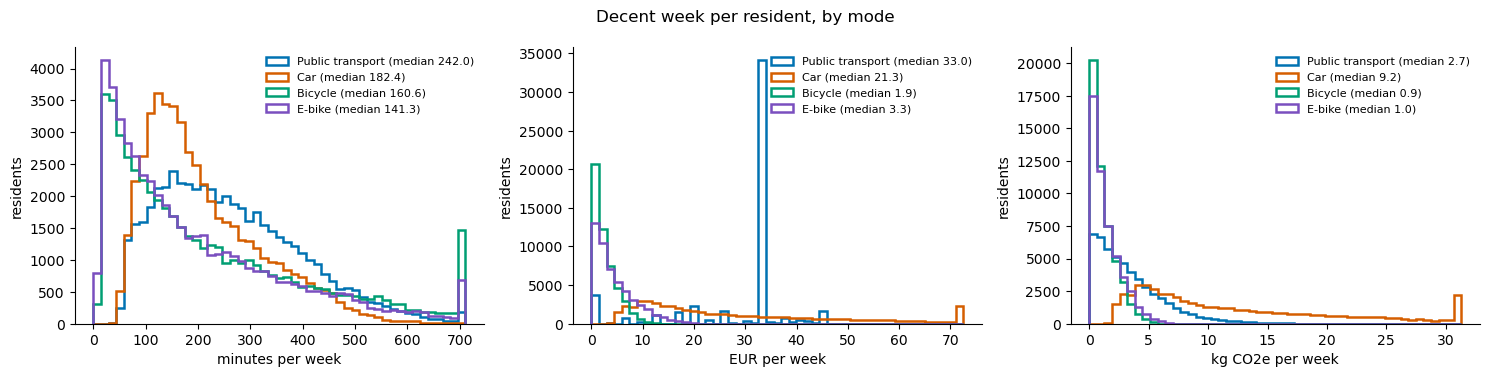

In [16]:
MODE_COLOURS = {"pt": "#0072B2", "car": "#D55E00", "bike": "#009E73", "ebike": "#7a4fbf"}
figure, axes = plt.subplots(ncols=len(CURRENCIES), figsize=(5 * len(CURRENCIES), 3.8))
for axis, currency in zip(axes, CURRENCIES):
    label, scale = UNITS[currency]
    rows = week.loc[week["currency"] == currency, MODES] * scale
    upper = np.nanpercentile(rows.values, 99)
    bins = np.linspace(0, upper, 50)
    for mode in MODES:
        axis.hist(rows[mode].clip(upper=upper), bins=bins, histtype="step", linewidth=1.8,
                  color=MODE_COLOURS[mode], label=f"{MODE_LABELS[mode]} (median {rows[mode].median():.1f})")
    axis.set_xlabel(label)
    axis.set_ylabel("residents")
    axis.legend(frameon=False, fontsize=8)
    axis.spines[["top", "right"]].set_visible(False)
figure.suptitle("Decent week per resident, by mode")
figure.tight_layout()

## 4. Summary per postal code

Across the residents of a postal code: median, mean, quartiles and count of the
weekly cost per mode and of the difference and ratio of each alternative against
the reference mode, per currency. Separately, the share of residents for whom the
alternative costs less, and the summary of the price of carbon in time and money. Postal codes
with fewer residents than the minimum are kept but flagged.

In [17]:
def summarise(frame, value):
    '''Median, mean, quartiles and resident count of one column across the residents of each postal code.'''
    grouped = frame.groupby(KEY, observed=True)[value]
    out = (
        grouped.agg(n_users="size", median="median", mean="mean")
        .join(grouped.quantile(0.25).rename("p25"))
        .join(grouped.quantile(0.75).rename("p75"))
    )
    out["enough_users"] = out["n_users"] >= MIN_USERS_PER_POSTAL_CODE
    return out.reset_index()


METRICS = [
    *MODES,
    *[f"{alt}_minus_{REFERENCE_MODE}" for alt in ALTERNATIVES],
    *[f"{alt}_over_{REFERENCE_MODE}" for alt in ALTERNATIVES],
]
pieces = []
for currency in CURRENCIES:
    rows = week.loc[week["currency"] == currency]
    for metric in METRICS:
        pieces.append(summarise(rows, metric).assign(currency=currency, metric=metric))
by_postal_code = pd.concat(pieces, ignore_index=True)
by_postal_code.to_parquet(RESULTS / "decent_week_by_postal_code.parquet", index=False)

below = week[["user_id", *KEY, "currency"]].copy()
for alt in ALTERNATIVES:
    below[f"{alt}_below_{REFERENCE_MODE}"] = week[alt] < week[REFERENCE_MODE]
share_below = (
    below.groupby([*KEY, "currency"], observed=True)
    .agg(n_users=("user_id", "size"),
         **{f"{alt}_below_{REFERENCE_MODE}": (f"{alt}_below_{REFERENCE_MODE}", "mean") for alt in ALTERNATIVES})
    .reset_index()
)
share_below["enough_users"] = share_below["n_users"] >= MIN_USERS_PER_POSTAL_CODE
share_below.to_parquet(RESULTS / "share_below_reference_by_postal_code.parquet", index=False)

price_by_postal_code = pd.concat(
    [
        summarise(
            price.loc[(price["alternative"] == alt) & (price["currency"] == currency)].dropna(subset=["price_per_kg"]),
            "price_per_kg",
        ).assign(alternative=alt, currency=currency)
        for alt in ALTERNATIVES for currency in PRICE_CURRENCIES
    ],
    ignore_index=True,
)
price_by_postal_code.to_parquet(RESULTS / "price_of_carbon_by_postal_code.parquet", index=False)

for currency, (label, scale) in UNITS.items():
    rows = by_postal_code.loc[(by_postal_code["currency"] == currency) & by_postal_code["enough_users"]]
    wide = rows.pivot_table(index=[*KEY, "n_users"], columns="metric", values="median")[METRICS]
    scaled = [m for m in METRICS if "_over_" not in m]
    wide[scaled] = wide[scaled] * scale
    wide.round(3).to_csv(RESULTS / f"decent_week_{currency}.csv")

print(f"{by_postal_code['Posnro'].nunique()} postal codes, "
      f"{by_postal_code.loc[by_postal_code['enough_users'], 'Posnro'].nunique()} with enough residents")
by_postal_code.head()

163 postal codes, 155 with enough residents


,Posnro,Nimi,Kunta,n_users,median,mean,p25,p75,enough_users,currency,metric
0,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,990,108.15,123.124646,76.300,145.575,True,time_min,pt
1,00120,Punavuori,Helsinki,297,84.50,104.060606,65.500,116.500,True,time_min,pt
2,00130,Kaartinkaupunki,Helsinki,60,100.25,124.958333,70.775,145.375,True,time_min,pt
3,00140,Kaivopuisto - Ullanlinna,Helsinki,240,120.00,134.873333,92.075,160.375,True,time_min,pt
4,00150,Eira - Hernesaari,Helsinki,459,122.00,136.283442,86.500,159.250,True,time_min,pt


### Check: the postal-code tables

The resident count is the same for every metric and currency within a postal code,
because all residents have all values. Then the postal codes below the minimum and
the two other tables saved in this section.

In [18]:
n_per_postal = by_postal_code.groupby("Posnro")["n_users"].nunique()
assert (n_per_postal == 1).all()
print("Postal codes below the minimum number of residents:")
by_postal_code.loc[~by_postal_code["enough_users"]].drop_duplicates("Posnro")[["Posnro", "Nimi", "Kunta", "n_users"]].reset_index(drop=True)

Postal codes below the minimum number of residents:


,Posnro,Nimi,Kunta,n_users
0,00310,Kivihaka,Helsinki,19
1,00880,Roihupellon teollisuusalue,Helsinki,19
2,01530,Veromiehenkylä,Vantaa,15
3,01720,Petikko,Vantaa,2
4,01740,Tuupakan teollisuusalue,Vantaa,11
5,01750,Keimola,Vantaa,11
6,01770,Martinlaakson teollisuusalue,Vantaa,1
7,02380,Suvisaaristo,Espoo,3


In [19]:
# Share of residents for whom the alternative costs less than the car, per currency
share_below.loc[share_below["enough_users"]].pivot_table(
    index=["Kunta", "Nimi"], columns="currency",
    values=[f"{alt}_below_{REFERENCE_MODE}" for alt in ALTERNATIVES],
).round(2).sort_values((f"pt_below_{REFERENCE_MODE}", "time_min"), ascending=False).head(20)

bike_below_car                     \
currency                                        co2_g money_eur time_min   
Kunta    Nimi                                                              
Helsinki Punavuori                                1.0       1.0     0.98   
         Helsinki Keskusta - Etu-Töölö            1.0       1.0     0.96   
         Kamppi - Ruoholahti                      1.0       1.0     0.98   
         Kaartinkaupunki                          1.0       1.0     0.97   
         Kruununhaka                              1.0       1.0     0.99   
         Kaivopuisto - Ullanlinna                 1.0       1.0     1.00   
         Eira - Hernesaari                        1.0       1.0     0.97   
         Kallio                                   1.0       1.0     0.98   
         Keski-Töölö                              1.0       1.0     0.92   
         Jätkäsaari                               1.0       1.0     0.98   
         Puotinharju                              1.0       1.0     0.46   
         Katajanokka                              1.0       1.0     0.97   
Espoo    Matinkylä                                1.0       1.0     0.66   
         Länsikorkee-Suvikumpu                    1.0       1.0     0.70   
         Olari                                    1.0       1.0     0.66   
Helsinki Lassila                                  1.0       1.0     0.89   
Espoo    Otsolahti                                1.0       1.0     0.63   
         Soukka                                   1.0       1.0     0.39   
         Tapiola                                  1.0       1.0     0.71   
         Otaniemi                                 1.0       1.0     0.50   

                                       ebike_below_car                     \
currency                                         co2_g money_eur time_min   
Kunta    Nimi                                                               
Helsinki Punavuori                                 1.0       1.0     0.98   
         Helsinki Keskusta - Etu-Töölö             1.0       1.0     0.98   
         Kamppi - Ruoholahti                       1.0       1.0     0.98   
         Kaartinkaupunki                           1.0       1.0     0.98   
         Kruununhaka                               1.0       1.0     1.00   
         Kaivopuisto - Ullanlinna                  1.0       1.0     1.00   
         Eira - Hernesaari                         1.0       1.0     0.99   
         Kallio                                    1.0       1.0     0.99   
         Keski-Töölö                               1.0       1.0     0.96   
         Jätkäsaari                                1.0       1.0     0.99   
         Puotinharju                               1.0       1.0     0.77   
         Katajanokka                               1.0       1.0     0.98   
Espoo    Matinkylä                                 1.0       1.0     0.72   
         Länsikorkee-Suvikumpu                     1.0       1.0     0.91   
         Olari                                     1.0       1.0     0.72   
Helsinki Lassila                                   1.0       1.0     0.96   
Espoo    Otsolahti                                 1.0       1.0     0.91   
         Soukka                                    1.0       1.0     0.54   
         Tapiola                                   1.0       1.0     0.88   
         Otaniemi                                  1.0       1.0     0.85   

                                       pt_below_car                     
currency                                      co2_g money_eur time_min  
Kunta    Nimi                                                           
Helsinki Punavuori                              1.0      0.48     0.90  
         Helsinki Keskusta - Etu-Töölö          1.0      0.35     0.88  
         Kamppi - Ruoholahti                    1.0      0.31     0.80  
         Kaartinkaupunki                        1.0      0.67     0.75  
       

In [20]:
# Price of carbon per postal code: minutes and euros per kg CO2e saved, both alternatives
price_by_postal_code.loc[price_by_postal_code["enough_users"]].pivot_table(
    index=["Kunta", "Nimi"], columns=["currency", "alternative"], values=["median", "n_users"],
).round(1).sort_values(("median", "time_min", "pt")).head(20)

median                            \
currency                               money_eur            time_min         
alternative                                 bike ebike   pt     bike ebike   
Kunta    Nimi                                                                
Helsinki Punavuori                          -2.3  -2.3  0.4    -22.3 -23.1   
         Helsinki Keskusta - Etu-Töölö      -2.3  -2.3  2.1    -22.5 -23.5   
         Kamppi - Ruoholahti                -2.3  -2.3  2.6    -20.7 -21.7   
         Kaartinkaupunki                    -2.3  -2.3 -2.4    -22.8 -23.8   
         Kruununhaka                        -2.3  -2.3  2.8    -21.0 -22.3   
         Kallio                             -2.3  -2.3  3.1    -19.0 -20.4   
         Eira - Hernesaari                  -2.3  -2.3  1.6    -19.6 -20.8   
         Kaivopuisto - Ullanlinna           -2.3  -2.3 -2.5    -19.8 -20.9   
         Jätkäsaari                         -2.3  -2.2  3.1    -18.5 -20.2   
         Puotinharju                        -2.3  -2.2 -0.8      0.7  -1.8   
         Keski-Töölö                        -2.3  -2.2  2.9    -17.5 -19.2   
Espoo    Matinkylä                          -2.3  -2.2  0.3    -11.4 -12.8   
Helsinki Katajanokka                        -2.3  -2.2  3.0    -16.2 -18.2   
Espoo    Olari                              -2.3  -2.2  1.8    -11.2 -12.2   
Helsinki Lassila                            -2.3  -2.2  0.5     -3.4  -6.1   
Espoo    Otaniemi                           -2.3  -2.2  0.2      0.2  -2.6   
         Soukka                             -2.3  -2.2  0.2      1.7  -0.5   
Helsinki Kuusisaari-Lehtisaari              -2.3  -2.2  1.8     -1.7  -4.4   
Espoo    Tapiola                            -2.3  -2.2 -0.5    -19.4 -21.2   
Helsinki Kannelmäki                         -2.3  -2.2 -0.1     -1.8  -4.2   

                                              n_users                  \
currency                                    money_eur                   
alternative                              pt      bike   ebike      pt   
Kunta    Nimi                                                           
Helsinki Punavuori                     -8.8     297.0   297.0   297.0   
         Helsinki Keskusta - Etu-Töölö -8.3     990.0   990.0   990.0   
         Kamppi - Ruoholahti           -6.2     557.0   557.0   557.0   
         Kaartinkaupunki               -5.6      60.0    60.0    60.0   
         Kruununhaka                   -4.7     229.0   229.0   229.0   
         Kallio                        -4.6     444.0   444.0   444.0   
         Eira - Hernesaari             -3.7     459.0   459.0   459.0   
         Kaivopuisto - Ullanlinna      -2.8     240.0   240.0   240.0   
         Jätkäsaari                    -2.0     272.0   272.0   272.0   
         Puotinharju                   -0.9      61.0    61.0    61.0   
         Keski-Töölö                   -0.9     136.0   136.0   136.0   
Espoo    Matinkylä                      1.3    1174.0  1174.0  1174.0   
Helsinki Katajanokka                    1.4     226.0   226.0   226.0   
Espoo    Olari                          1.7     611.0   611.0   611.0   
Helsinki Lassila                        1.7     107.0   107.0   107.0   
Espoo    Otaniemi                       2.0      60.0    60.0    60.0   
         Soukka                         2.2     473.0   473.0   473.0   
Helsinki Kuusisaari-Lehtisaari          2.3      32.0    32.0    32.0   
Espoo    Tapiola                        2.4     163.0   163.0   163.0   
Helsinki Kannelmäki                     2.6     350.0   350.0   350.0   

                                                                 
currency                               time_min                  
alternative                                bike   ebike      pt  
Kunta    Nimi                                                    
Helsinki Punavuori                        297.0   297.0   297.0  
         Helsinki Keskusta - Etu-Töölö    990.0   990.0   990.0  
         Kamppi - Ru

### Weekly cost by mode, median across residents

Minutes, euros and kg CO₂e per week for the postal codes with enough residents,
sorted by the public transport time.

In [21]:
def postal_table(currency, metrics=MODES, statistic="median"):
    '''Postal codes x metrics for one currency, scaled to the display unit, enough residents only.'''
    label, scale = UNITS[currency]
    rows = by_postal_code.loc[
        (by_postal_code["currency"] == currency) & by_postal_code["metric"].isin(metrics)
        & by_postal_code["enough_users"]
    ]
    table = rows.pivot(index=["Kunta", "Nimi"], columns="metric", values=statistic)[list(metrics)]
    unscaled = [m for m in metrics if "_over_" in m]
    table[[m for m in metrics if m not in unscaled]] *= scale
    return table


table = pd.concat({UNITS[c][0]: postal_table(c) for c in CURRENCIES}, axis=1).round(1)
table.sort_values(("minutes per week", "pt")).head(20)

minutes per week                     \
metric                                               pt    car  bike ebike   
Kunta    Nimi                                                                
Helsinki Punavuori                                 84.5  124.4  26.9  23.7   
         Kaartinkaupunki                          100.2  127.8  30.3  26.6   
         Helsinki Keskusta - Etu-Töölö            108.2  147.3  35.8  31.5   
         Kallio                                   109.5  130.0  42.2  37.1   
         Sörnäinen                                114.4   89.0  40.1  35.2   
         Kamppi - Ruoholahti                      115.0  149.0  42.5  37.4   
         Itä-Pasila                               117.6   98.8  45.7  40.2   
Espoo    Tapiola                                  119.0  109.7  35.8  31.5   
Helsinki Kaivopuisto - Ullanlinna                 120.0  128.9  35.9  31.5   
         Eira - Hernesaari                        122.0  131.0  38.1  33.5   
         Etu-Vallila - Alppila                    124.6   94.6  50.9  44.8   
         Kruununhaka                              124.8  147.0  41.9  36.9   
         Katajanokka                              153.0  156.9  63.0  55.4   
         Vallila                                  153.4  122.1  68.0  59.8   
Espoo    Etelä-Leppävaara                         155.0  117.4  60.0  52.8   
Helsinki Taka-Töölö                               157.2  138.9  75.8  66.6   
         Keski-Töölö                              157.5  165.5  66.5  58.4   
Espoo    Olari                                    164.6  163.2  76.6  67.4   
Helsinki Vattuniemi                               170.1  140.0  98.9  86.9   
         Jätkäsaari                               171.0  178.5  71.9  63.2   

                                       EUR per week                   \
metric                                           pt   car bike ebike   
Kunta    Nimi                                                          
Helsinki Punavuori                             16.5  10.3  0.3   0.5   
         Kaartinkaupunki                        0.0  10.9  0.4   0.6   
         Helsinki Keskusta - Etu-Töölö         33.0  11.7  0.4   0.7   
         Kallio                                33.0  10.4  0.5   0.9   
         Sörnäinen                             23.1   7.8  0.5   0.8   
         Kamppi - Ruoholahti                   33.0  12.1  0.5   0.9   
         Itä-Pasila                            33.0   8.4  0.5   0.9   
Espoo    Tapiola                               16.5   8.5  0.4   0.7   
Helsinki Kaivopuisto - Ullanlinna               0.0  11.2  0.4   0.7   
         Eira - Hernesaari                     26.4  11.4  0.5   0.8   
         Etu-Vallila - Alppila                 33.0   8.5  0.6   1.0   
         Kruununhaka                           33.0  12.2  0.5   0.9   
         Katajanokka                           33.0  12.7  0.8   1.3   
         Vallila                               33.0  10.7  0.8   1.4   
Espoo    Etelä-Leppävaara                      33.0  10.5  0.7   1.2   
Helsinki Taka-Töölö                            33.0  12.3  0.9   1.5   
         Keski-Töölö                           33.0  14.0  0.8   1.4   
Espoo    Olari                                 33.0  18.3  0.9   1.6   
Helsinki Vattuniemi                            33.0  14.3  1.2   2.0   
         Jätkäsaari                            33.0  14.7  0.9   1.5   

                                       kg CO2e per week                  
metric                                               pt  car bike ebike  
Kunta    Nimi                                                            
Helsinki Punavuori                                  0.3  4.4  0.1   0.2  
         Kaartinkaupunki                            0.3  4.7  0.2   0.2  
         Helsinki Keskusta - Etu-Töölö              0.4  5.1  0.2   0.2  
         Kallio                                     0.5  4.5  0.2   0.3  
         Sörnäinen                                  0.5  3.4  0.2   0

### Advantage of the alternatives over the car

Per postal code: the median difference of each alternative against the car in the
three currencies, the share of residents for whom the alternative is faster, and
the median price of carbon in minutes and in euros per kg saved. Sorted by the extra minutes of public transport.

In [22]:
advantage = pd.concat(
    {UNITS[c][0]: postal_table(c, [f"{alt}_minus_{REFERENCE_MODE}" for alt in ALTERNATIVES]) for c in CURRENCIES},
    axis=1,
)
shares = (
    share_below.loc[share_below["enough_users"] & (share_below["currency"] == "time_min")]
    .set_index(["Kunta", "Nimi"])[[f"{alt}_below_{REFERENCE_MODE}" for alt in ALTERNATIVES]]
)
shares.columns = pd.MultiIndex.from_product([["share faster than car"], ALTERNATIVES])
prices = price_by_postal_code.loc[price_by_postal_code["enough_users"]].pivot_table(
    index=["Kunta", "Nimi"], columns=["currency", "alternative"], values="median",
)
prices.columns = pd.MultiIndex.from_tuples([(PRICE_UNITS[currency], alt) for currency, alt in prices.columns])
advantage = advantage.join(shares).join(prices).round(2)
advantage.sort_values(("minutes per week", f"pt_minus_{REFERENCE_MODE}")).head(20)

minutes per week                 \
                                           pt_minus_car bike_minus_car   
Kunta    Nimi                                                            
Helsinki Helsinki Keskusta - Etu-Töölö           -40.25        -105.31   
         Punavuori                               -37.45         -95.36   
         Kamppi - Ruoholahti                     -30.15        -101.06   
         Kaartinkaupunki                         -28.15         -99.21   
         Kruununhaka                             -24.15        -102.45   
         Kallio                                  -16.95         -80.76   
         Eira - Hernesaari                       -16.20         -94.15   
         Jätkäsaari                              -12.72        -109.49   
         Kaivopuisto - Ullanlinna                -12.10         -92.54   
         Keski-Töölö                              -4.87         -95.89   
         Puotinharju                              -4.20           7.44   
         Katajanokka                               5.66         -75.14   
Espoo    Matinkylä                                 7.80         -64.47   
         Tapiola                                   8.34         -56.45   
         Olari                                     9.60         -47.50   
Helsinki Lassila                                  10.95         -43.73   
Espoo    Otsolahti                                12.45         -38.26   
Helsinki Vallila                                  13.65         -57.83   
         Kuusisaari-Lehtisaari                    13.91         -18.86   
Espoo    Länsikorkee-Suvikumpu                    15.20         -50.27   

                                                       EUR per week  \
                                       ebike_minus_car pt_minus_car   
Kunta    Nimi                                                         
Helsinki Helsinki Keskusta - Etu-Töölö         -109.84        13.29   
         Punavuori                              -98.93         2.03   
         Kamppi - Ruoholahti                   -105.08        15.90   
         Kaartinkaupunki                       -101.74        -9.42   
         Kruununhaka                           -108.10        16.36   
         Kallio                                 -89.43        16.01   
         Eira - Hernesaari                      -98.58         8.34   
         Jätkäsaari                            -117.84        17.62   
         Kaivopuisto - Ullanlinna               -96.88        -9.67   
         Keski-Töölö                           -102.39        17.13   
         Puotinharju                            -32.06        -9.00   
         Katajanokka                            -85.99        12.36   
Espoo    Matinkylä                              -72.38         2.16   
         Tapiola                                -60.77        -4.48   
         Olari                                  -53.34         9.32   
Helsinki Lassila                                -56.99         3.82   
Espoo    Otsolahti                              -56.61         8.73   
Helsinki Vallila                                -64.08        12.61   
         Kuusisaari-Lehtisaari                  -47.27         9.03   
Espoo    Länsikorkee-Suvikumpu                  -64.98         7.36   

                                                                       \
                                       bike_minus_car ebike_minus_car   
Kunta    Nimi                                                           
Helsinki Helsinki Keskusta - Etu-Töölö         -11.27          -10.95   
         Punavuori                              -9.95           -9.73   
         Kamppi - Ruoholahti                   -11.56          -11.24   
         Kaartinkaupunki                       -10.50          -10.24   
         Kruununhaka                           -11.69          -11.35   
         Kallio                                -10.04           -9.73   
         Eira - Hernesaari                   

## 5. Near trip per category: where each mode competes

The same comparison per category and without the weekly weights: per postal code,
the median near trip per mode and the median across residents of the log₂ ratio of
each alternative against the car (0 means equal cost, 1 means twice the cost, −1
half). Healthcare and education appear here even though they carry no weekly tour.

In [23]:
by_category_user = (
    trips.pivot_table(index=["user_id", *KEY, "poi_type", "currency"], columns="mode", values="trip")
    .reset_index()
)
for alt in ALTERNATIVES:
    with np.errstate(divide="ignore", invalid="ignore"):
        by_category_user[f"log2_{alt}_over_{REFERENCE_MODE}"] = np.log2(
            by_category_user[alt] / by_category_user[REFERENCE_MODE]
        )

CATEGORY_METRICS = [*MODES, *[f"log2_{alt}_over_{REFERENCE_MODE}" for alt in ALTERNATIVES]]
pieces = []
for currency in CURRENCIES:
    rows = by_category_user.loc[by_category_user["currency"] == currency]
    for category in CATEGORIES:
        sub = rows.loc[rows["poi_type"] == category]
        for metric in CATEGORY_METRICS:
            valid = sub.loc[np.isfinite(sub[metric])]
            pieces.append(
                summarise(valid, metric).assign(currency=currency, poi_type=category, metric=metric)
            )
by_category = pd.concat(pieces, ignore_index=True)
by_category.to_parquet(RESULTS / "near_trip_by_postal_code_and_category.parquet", index=False)


def category_table(currency, metric, statistic="median"):
    '''Postal codes x categories for one currency and metric, enough residents only.'''
    rows = by_category.loc[
        (by_category["currency"] == currency) & (by_category["metric"] == metric) & by_category["enough_users"]
    ]
    return rows.pivot(index=["Kunta", "Nimi"], columns="poi_type", values=statistic)[CATEGORIES]


category_table("time_min", f"log2_pt_over_{REFERENCE_MODE}").round(2).sort_values("Shopping, Errands").head(20)

poi_type                                Shopping, Errands  Social, Cultural  \
Kunta    Nimi                                                                 
Helsinki Punavuori                                  -0.57             -0.53   
         Helsinki Keskusta - Etu-Töölö              -0.43             -0.44   
         Kamppi - Ruoholahti                        -0.32             -0.32   
         Kaartinkaupunki                            -0.27             -0.53   
         Kruununhaka                                -0.27             -0.27   
         Kallio                                     -0.25             -0.25   
         Eira - Hernesaari                          -0.20             -0.21   
         Kaivopuisto - Ullanlinna                   -0.16             -0.14   
         Jätkäsaari                                 -0.10             -0.10   
         Puotinharju                                -0.09             -0.07   
         Keski-Töölö                                -0.07             -0.07   
Espoo    Olari                                       0.01              0.01   
         Matinkylä                                   0.02              0.02   
Helsinki Katajanokka                                 0.03              0.03   
Espoo    Otaniemi                                    0.07              0.08   
         Otsolahti                                   0.10              0.11   
         Tapiola                                     0.10              0.09   
Helsinki Kuusisaari-Lehtisaari                       0.11              0.13   
         Pitäjänmäen teollisuusalue                  0.12              0.11   
         Lassila                                     0.12              0.07   

poi_type                                Recreational, Outdoors  \
Kunta    Nimi                                                    
Helsinki Punavuori                                       -0.52   
         Helsinki Keskusta - Etu-Töölö                   -0.51   
         Kamppi - Ruoholahti                             -0.34   
         Kaartinkaupunki                                 -0.29   
         Kruununhaka                                     -0.25   
         Kallio                                          -0.21   
         Eira - Hernesaari                               -0.19   
         Kaivopuisto - Ullanlinna                        -0.11   
         Jätkäsaari                                      -0.11   
         Puotinharju                                     -0.02   
         Keski-Töölö                                     -0.02   
Espoo    Olari                                            0.17   
         Matinkylä                                        0.14   
Helsinki Katajanokka                                      0.03   
Espoo    Otaniemi                                         0.17   
         Otsolahti                                        0.12   
         Tapiola                                          0.09   
Helsinki Kuusisaari-Lehtisaari                            0.14   
         Pitäjänmäen teollisuusalue                       0.21   
         Lassila                                          0.12   

poi_type                                Healthcare and Health  Education  
Kunta    Nimi                                                             
Helsinki Punavuori                                      -0.58      -0.51  
         Helsinki Keskusta - Etu-Töölö                  -0.48      -0.55  
         Kamppi - Ruoholahti                            -0.40      -0.40  
         Kaartinkaupunki                                -0.24      -0.63  
         Kruununhaka                                    -0.23      -0.28  
         Kallio                                         -0.29      -0.33  
         Eira - Hernesaari                              -0.20      -0.16  
         Kaivopuisto - Ullanlinna                       -0.13      -0.08  
         Jätkäsaari                                     -0

### Check: per-resident category rows and comparison with notebook 02.5

First the per-resident rows behind the category table. Then, for time and CO₂, the
median near trip per postal code and category from this notebook against the median
at the same threshold saved by `02.5` (`typical_trip_thresholds.parquet`). They
differ only because this notebook keeps the residents who have every routine
category in every mode and currency; the relative difference should be small and
centred on zero. Money has no counterpart in `02.5`.

In [24]:
by_category_user.head(10)

mode,user_id,Posnro,Nimi,Kunta,poi_type,currency,bike,car,ebike,pt,log2_pt_over_car,log2_bike_over_car,log2_ebike_over_car
0,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,co2_g,30.611790,899.970000,36.442607,56.326,-3.998004,-4.877718,-4.626179
1,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,money_eur,0.068512,2.084328,0.116471,0.000,-inf,-4.927080,-4.161545
2,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,time_min,5.716487,27.440000,5.026566,17.200,-0.673872,-2.263080,-2.448635
3,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Healthcare and Health,co2_g,30.611790,899.970000,36.442607,56.326,-3.998004,-4.877718,-4.626179
4,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Healthcare and Health,money_eur,0.068512,2.084328,0.116471,0.000,-inf,-4.927080,-4.161545
5,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Healthcare and Health,time_min,5.716487,27.440000,5.026566,17.200,-0.673872,-2.263080,-2.448635
6,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,"Recreational, Outdoors",co2_g,30.611790,899.970000,36.442607,56.326,-3.998004,-4.877718,-4.626179
7,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,"Recreational, Outdoors",money_eur,0.068512,2.084328,0.116471,0.000,-inf,-4.927080,-4.161545
8,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,"Recreational, Outdoors",time_min,5.716487,27.440000,5.026566,17.200,-0.673872,-2.263080,-2.448635
9,000241b5-3f14-45f2-b15d-bbaeb1083174,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,"Shopping, Errands",co2_g,30.611790,899.970000,36.442607,56.326,-3.998004,-4.877718,-4.626179


In [25]:
reference = pd.read_parquet(VISITATION / "typical_trip_thresholds.parquet")
reference = reference.loc[reference["poi_type"].isin(CATEGORIES)].rename(columns={f"at_{THRESHOLD}": "median_02_5"})
mine = by_category.loc[by_category["metric"].isin(MODES) & by_category["enough_users"]].rename(columns={"metric": "mode", "median": "median_here"})
compare = mine.merge(reference[["Posnro", "poi_type", "mode", "currency", "median_02_5"]], on=["Posnro", "poi_type", "mode", "currency"], how="inner")
compare["relative_difference"] = compare["median_here"] / compare["median_02_5"] - 1
print(f"{len(compare):,} postal code x category x mode x currency cells compared")
compare.groupby(["mode", "currency"])["relative_difference"].describe(percentiles=[0.05, 0.5, 0.95]).round(3)

6,192 postal code x category x mode x currency cells compared


count   mean    std    min     5%    50%    95%    max
mode  currency                                                        
bike  co2_g     774.0  0.021  0.077 -0.329 -0.055  0.002  0.122  0.647
      time_min  774.0  0.021  0.077 -0.329 -0.055  0.002  0.122  0.647
car   co2_g     774.0  0.022  0.077 -0.301 -0.034  0.004  0.121  1.075
      time_min  774.0  0.013  0.051 -0.219 -0.030  0.002  0.075  0.792
ebike co2_g     774.0  0.021  0.077 -0.329 -0.055  0.002  0.122  0.647
      time_min  774.0  0.021  0.077 -0.329 -0.055  0.002  0.122  0.647
pt    co2_g     774.0  0.013  0.062 -0.369 -0.061  0.000  0.102  0.670
      time_min  774.0  0.004  0.046 -0.361 -0.043  0.000  0.056  0.661

In [26]:
# The same comparison for one postal code and currency, all categories and modes
example_postal = compare["Posnro"].iloc[0]
compare.loc[(compare["Posnro"] == example_postal) & (compare["currency"] == "time_min")].pivot(
    index="poi_type", columns="mode", values=["median_here", "median_02_5", "n_users"]
).round(1)

median_here                   median_02_5              \
mode                          bike   car ebike    pt        bike   car ebike   
poi_type                                                                       
Education                      6.3  28.5   5.5  20.2         6.3  28.8   5.6   
Healthcare and Health          6.6  29.0   5.8  21.1         7.1  29.1   6.2   
Recreational, Outdoors         6.4  28.8   5.6  21.0         6.5  28.8   5.7   
Shopping, Errands              7.3  30.0   6.4  22.4         7.8  30.3   6.8   
Social, Cultural               7.2  29.5   6.3  22.1         7.4  30.1   6.5   

                             n_users                       
mode                      pt    bike    car  ebike     pt  
poi_type                                                   
Education               20.3   772.0  772.0  772.0  772.0  
Healthcare and Health   21.4   862.0  863.0  862.0  863.0  
Recreational, Outdoors  21.3   990.0  990.0  990.0  990.0  
Shopping, Errands       22.8   990.0  990.0  990.0  990.0  
Social, Cultural        22.4   990.0  990.0  990.0  990.0

## 6. Maps and charts

Maps use the median across residents and show only postal codes with enough
residents; the others stay grey. Sequential maps share one scale per currency so
the modes can be read against each other; the difference maps are centred on zero,
red where the alternative costs more than the car and blue where it costs less.

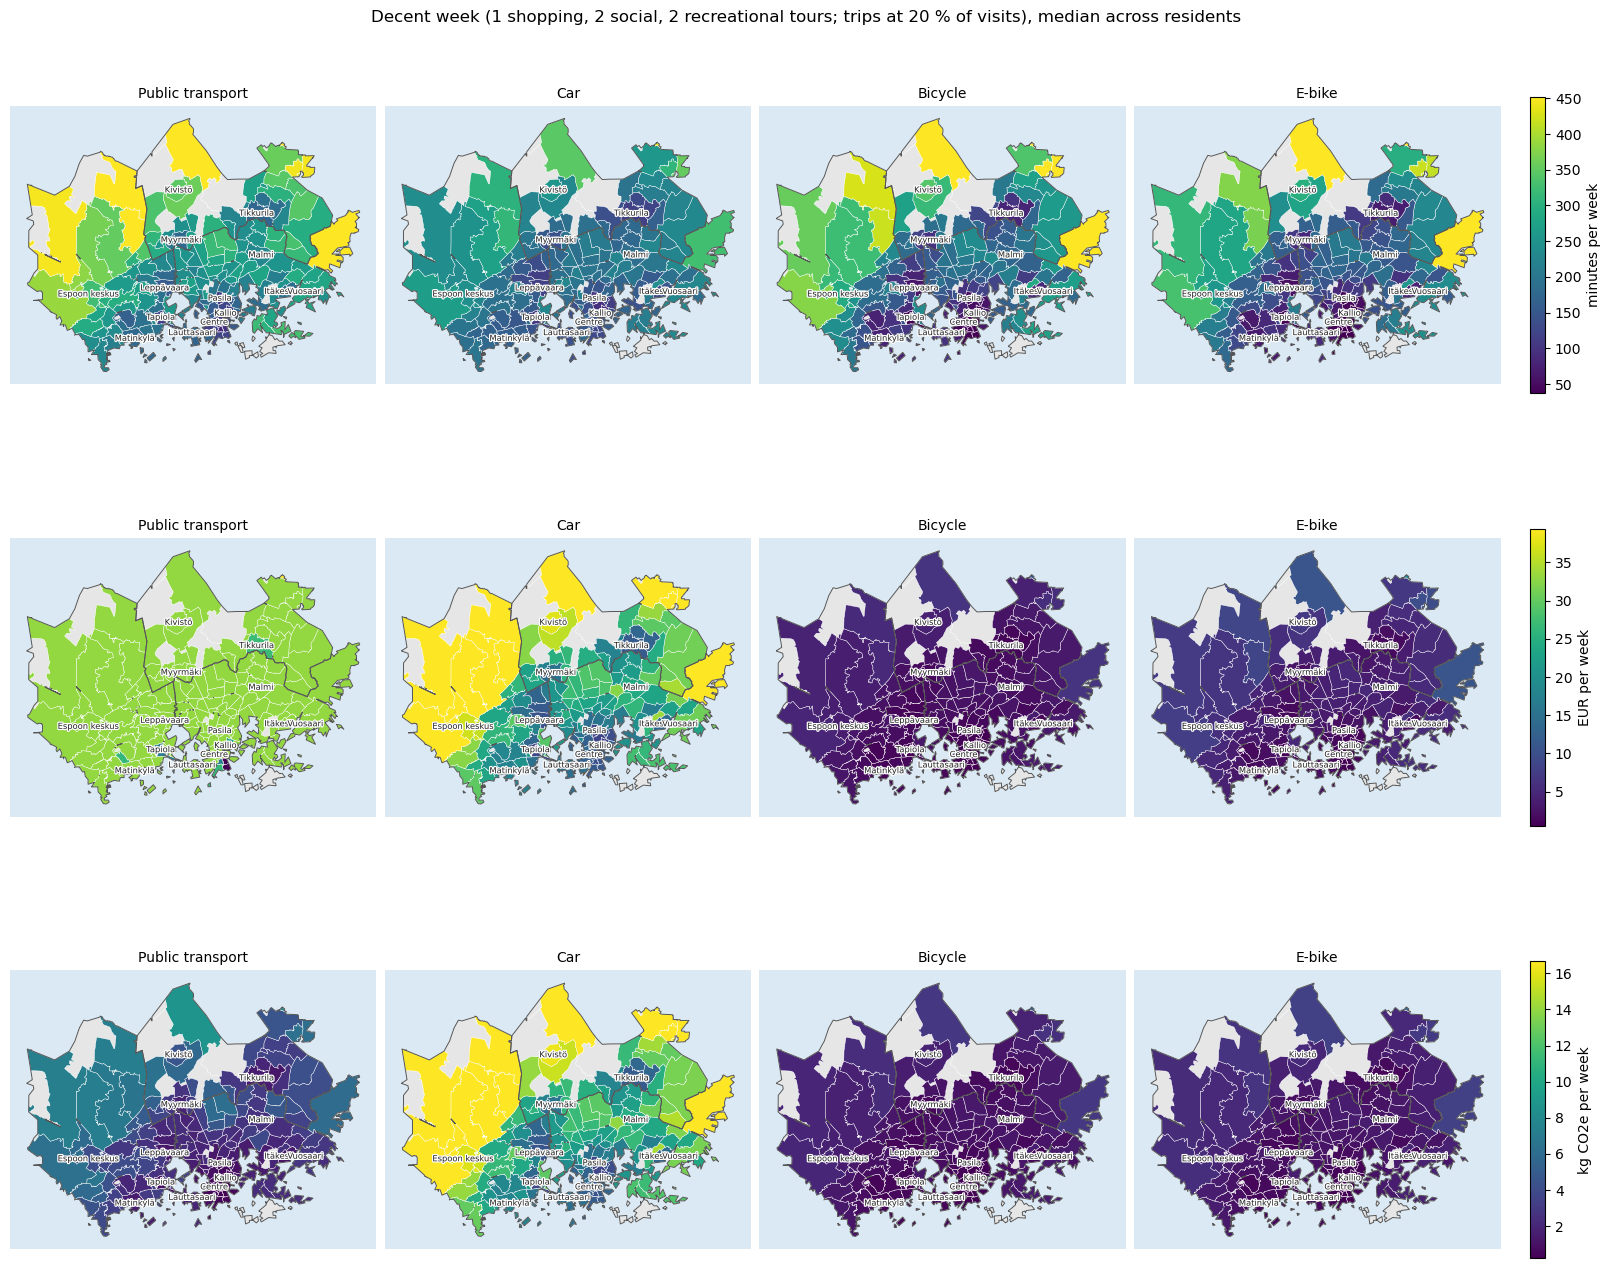

In [27]:
# 02380 Suvisaaristo (Espoo) is a 175 km2 polygon of mostly open sea reaching 27 km into the Gulf
# of Finland, with 3 residents in the data; it is left off the maps.
SEA_POSTAL_CODES = ["02380"]
postal = gpd.read_file(POSTAL_CODES)[["Posnro", "Nimi", "Kunta", "geometry"]]
postal = postal.loc[~postal["Posnro"].isin(SEA_POSTAL_CODES)].reset_index(drop=True)
KUNTA_COLOURS = {"Helsinki": "#0072B2", "Espoo": "#E69F00", "Vantaa": "#009E73"}
SEQUENTIAL, DIVERGING = "viridis", "RdBu_r"


def values_for(frame, statistic="median", **filters):
    '''Series indexed by postal code for one combination of columns, enough residents only.'''
    mask = frame["enough_users"].to_numpy(copy=True)
    for column, value in filters.items():
        mask &= (frame[column] == value).to_numpy()
    return frame.loc[mask].set_index("Posnro")[statistic]


# Sea polygons (OSM coastline, osmdata.openstreetmap.de simplified water polygons) cut the
# postal codes to land on the maps; municipal borders and a few place names orient the reader.
WATER_POLYGONS = SCRATCH / "carbon-advantage" / "basemap" / "simplified-water-polygons-split-3857" / "simplified_water_polygons.shp"
LANDMARKS = {
    "00100": "Centre", "00520": "Pasila", "00530": "Kallio", "00200": "Lauttasaari", "00700": "Malmi",
    "00930": "Itäkeskus", "00980": "Vuosaari", "02100": "Tapiola", "02600": "Leppävaara", "02230": "Matinkylä",
    "02770": "Espoon keskus", "01300": "Tikkurila", "01600": "Myyrmäki", "01700": "Kivistö",
}
water = gpd.read_file(WATER_POLYGONS, bbox=tuple(postal.to_crs(3857).total_bounds)).to_crs(postal.crs)
postal = postal.overlay(water[["geometry"]], how="difference")
municipalities = postal.dissolve("Kunta")
landmarks = postal.loc[postal["Posnro"].isin(LANDMARKS)].copy()
landmarks["label"] = landmarks["Posnro"].map(LANDMARKS)
landmarks["point"] = landmarks.geometry.representative_point()
SEA_COLOUR, HALO = "#dbe9f4", [patheffects.withStroke(linewidth=1.8, foreground="white")]


def draw(axis, values, cmap, vmin, vmax):
    """One choropleth of a series indexed by postal code, on land, with borders and place names."""
    shapes = postal.merge(values.rename("value"), left_on="Posnro", right_index=True, how="left")
    postal.plot(ax=axis, facecolor="#e6e6e6", edgecolor="white", linewidth=0.3)
    shapes.dropna(subset=["value"]).plot(
        ax=axis, column="value", cmap=cmap, vmin=vmin, vmax=vmax, edgecolor="white", linewidth=0.3
    )
    municipalities.boundary.plot(ax=axis, color="#555555", linewidth=0.7)
    for _, place in landmarks.iterrows():
        axis.annotate(place["label"], (place["point"].x, place["point"].y), ha="center", va="center",
                      fontsize=6, color="#222222", path_effects=HALO)
    axis.set_facecolor(SEA_COLOUR)
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)


def colourbar(figure, axes, cmap, vmin, vmax, label):
    mappable = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax))
    figure.colorbar(mappable, ax=list(axes), shrink=0.7, pad=0.02, label=label)


routine = ", ".join(f"{n} {c.split(',')[0].lower()}" for c, n in WEEKLY_VISITS.items() if n > 0)
figure, axes = plt.subplots(
    nrows=len(CURRENCIES), ncols=len(MODES),
    figsize=(4 * len(MODES), 4.4 * len(CURRENCIES)), constrained_layout=True,
)
for row, currency in zip(axes, CURRENCIES):
    label, scale = UNITS[currency]
    tables = {mode: values_for(by_postal_code, currency=currency, metric=mode) * scale for mode in MODES}
    vmin, vmax = np.nanpercentile(pd.concat(tables.values()), [2, 98])
    for axis, mode in zip(row, MODES):
        draw(axis, tables[mode], SEQUENTIAL, vmin, vmax)
        axis.set_title(MODE_LABELS[mode], fontsize=10)
    colourbar(figure, row, SEQUENTIAL, vmin, vmax, label)
figure.suptitle(f"Decent week ({routine} tours; trips at {THRESHOLD} % of visits), median across residents")
figure.savefig(RESULTS / "map_decent_week_by_mode.png", dpi=150)

### Difference against the car, per alternative and currency

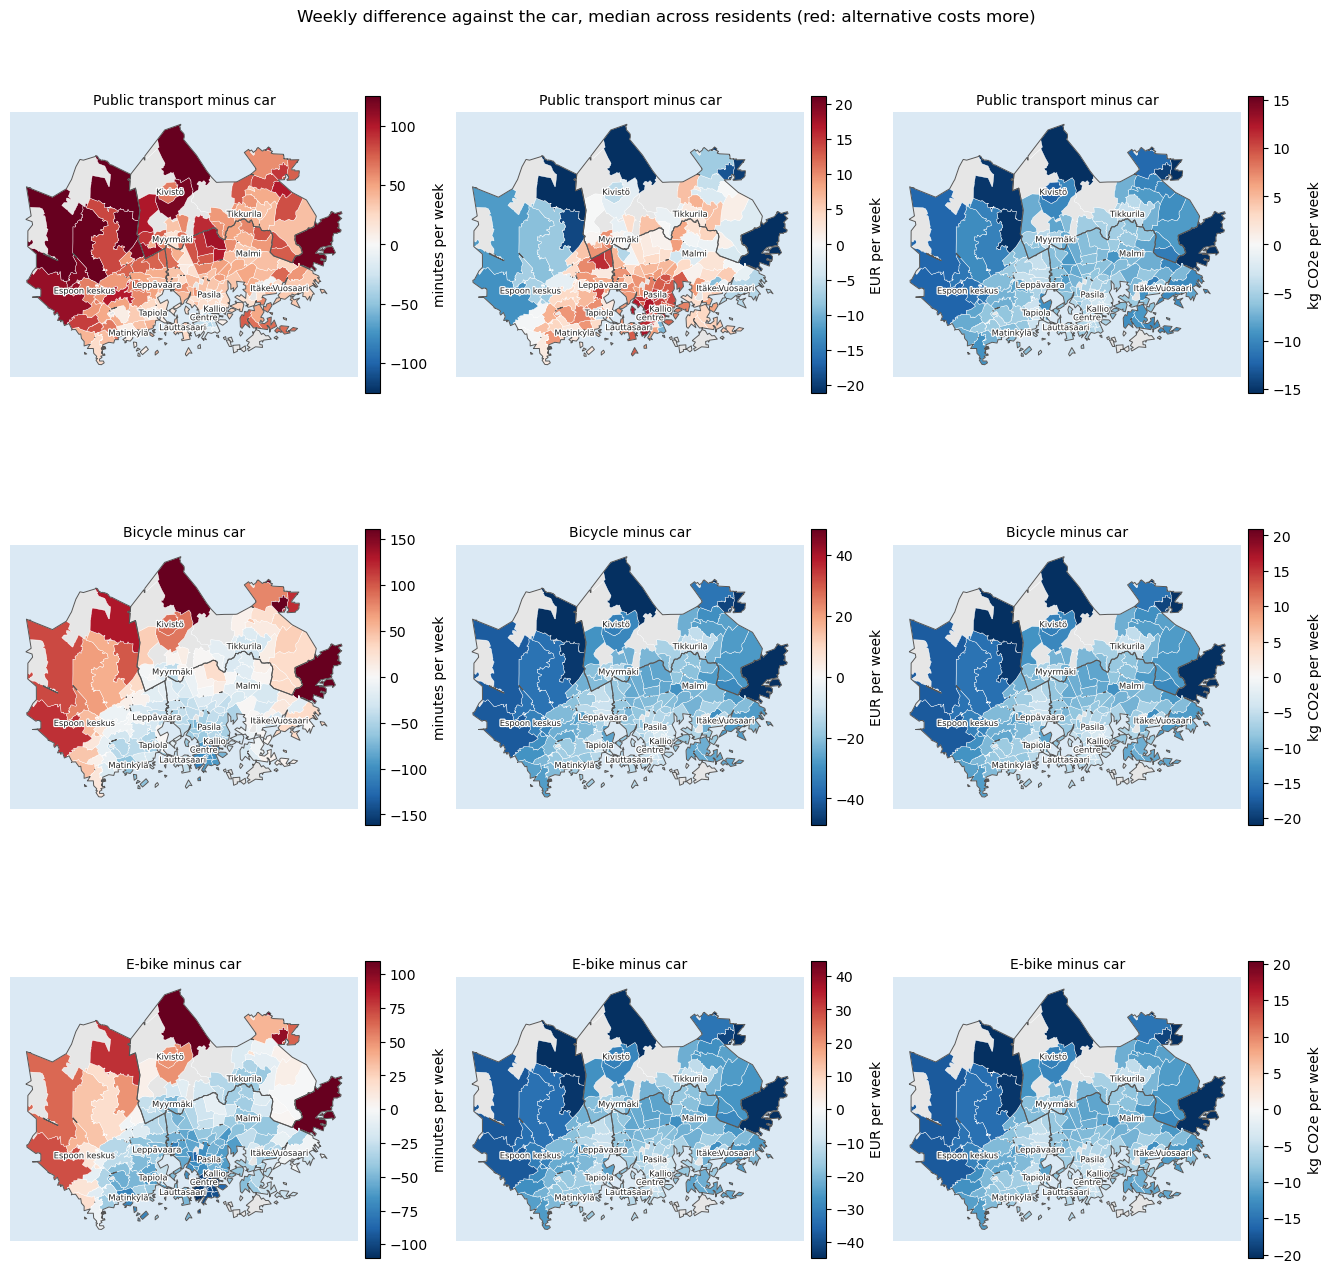

In [28]:
figure, axes = plt.subplots(
    nrows=len(ALTERNATIVES), ncols=len(CURRENCIES),
    figsize=(4.4 * len(CURRENCIES), 4.4 * len(ALTERNATIVES)), constrained_layout=True,
)
for row, alt in zip(axes, ALTERNATIVES):
    for axis, currency in zip(row, CURRENCIES):
        label, scale = UNITS[currency]
        values = values_for(by_postal_code, currency=currency, metric=f"{alt}_minus_{REFERENCE_MODE}") * scale
        limit = np.nanpercentile(values.abs(), 98)
        draw(axis, values, DIVERGING, -limit, limit)
        axis.set_title(f"{MODE_LABELS[alt]} minus {MODE_LABELS[REFERENCE_MODE].lower()}", fontsize=10)
        colourbar(figure, [axis], DIVERGING, -limit, limit, label)
figure.suptitle("Weekly difference against the car, median across residents (red: alternative costs more)")
figure.savefig(RESULTS / "map_difference_against_car.png", dpi=150)

### Time or money given up against carbon saved, one bubble per postal code

Each bubble is a postal code; its area grows with the number of residents in the
data (legend in the top-right panel), its colour is the municipality. The vertical
axis is the carbon the median resident saves per week by making the decent week with
the alternative instead of the car; every postal code sits above zero because all
three alternatives emit less than the car. The horizontal axis is what that switch
costs the same resident in that currency: on the green side the alternative is faster
(left panels) or cheaper (right panels) than the car, on the white side it is slower
or costlier. A bubble high up and on the green side is a place where leaving the car
pays in every currency. Car, bicycle and e-bike money and CO₂e are all linear in
distance, so their money panels collapse onto a line.


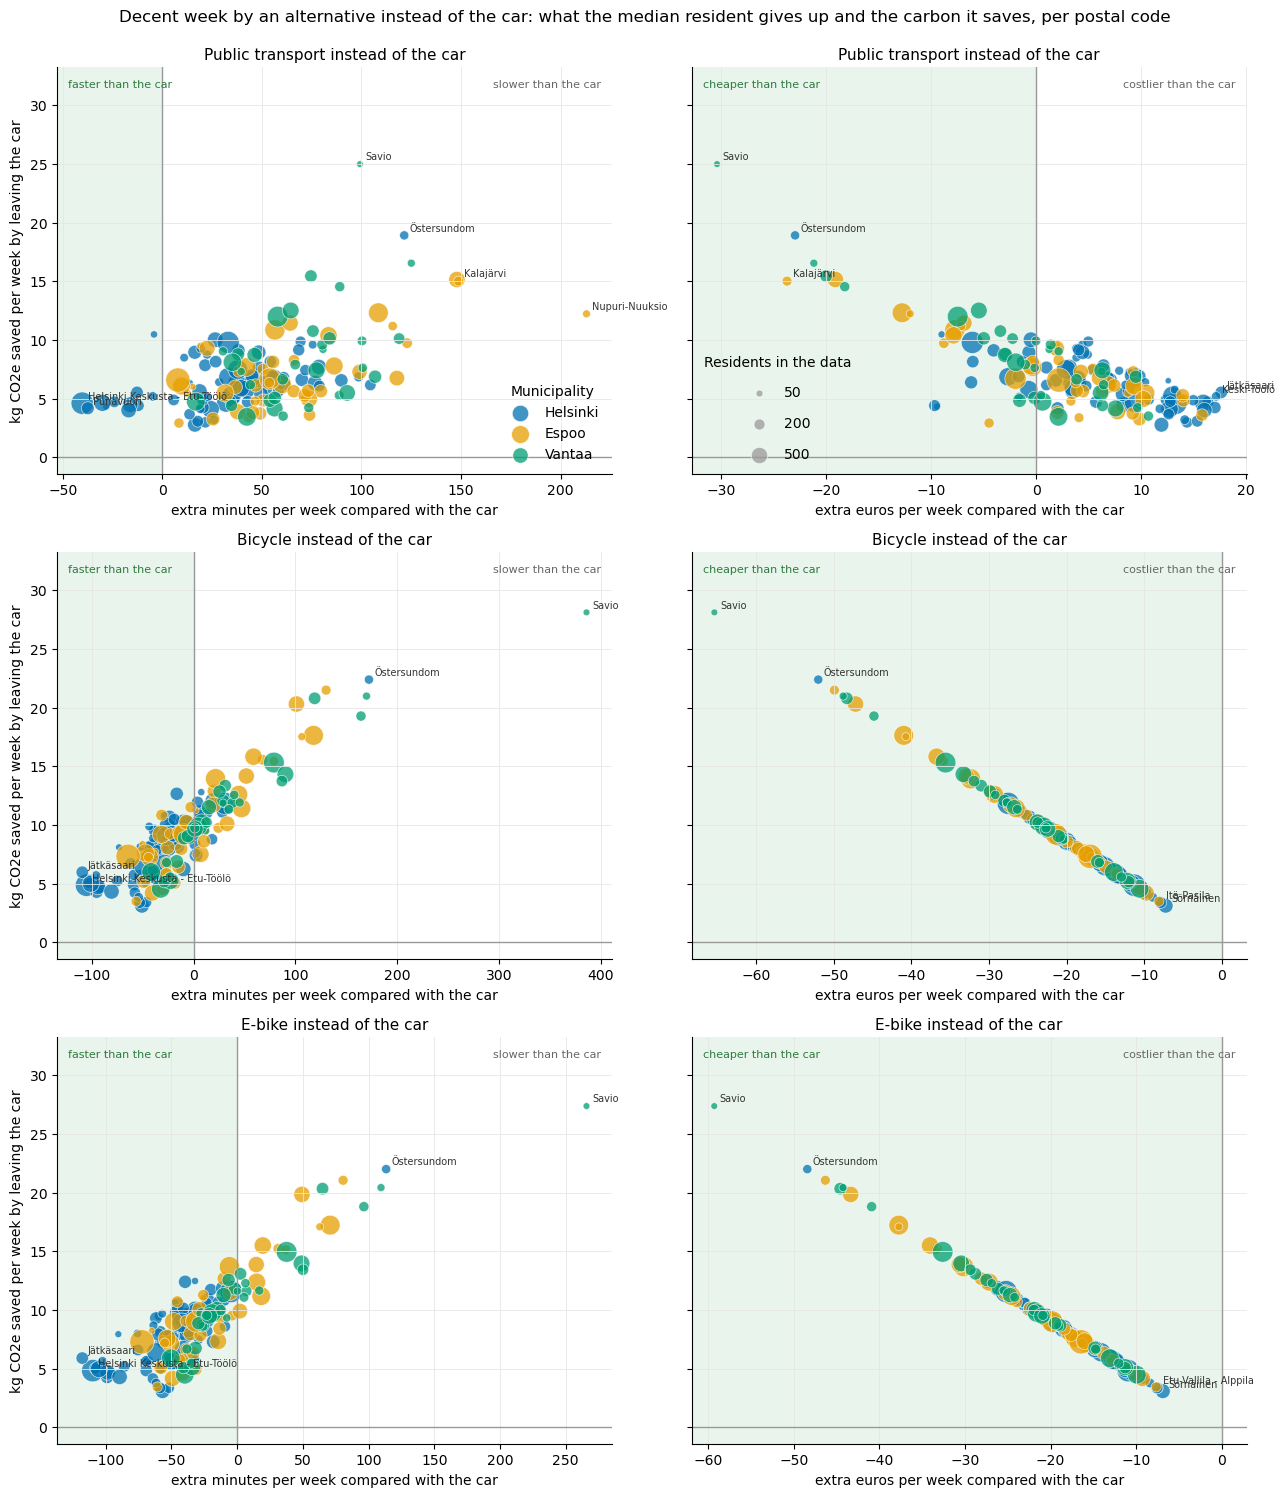

In [29]:
def advantage_points(alt):
    '''Per postal code: median extra minutes, extra euros and kg CO2e saved per week against the reference.'''
    metric = f"{alt}_minus_{REFERENCE_MODE}"
    points = pd.DataFrame({
        "extra_minutes": values_for(by_postal_code, currency="time_min", metric=metric),
        "extra_euros": values_for(by_postal_code, currency="money_eur", metric=metric),
        "saved_kg": -values_for(by_postal_code, currency="co2_g", metric=metric) / 1000,
        "n_users": values_for(by_postal_code, "n_users", currency="co2_g", metric=metric),
    })
    return points.join(postal.set_index("Posnro")[["Nimi", "Kunta"]])


# Panels: column, axis label, wording of the two sides of zero.
PANELS = [
    ("extra_minutes", "extra minutes per week compared with the car", ("faster than the car", "slower than the car")),
    ("extra_euros", "extra euros per week compared with the car", ("cheaper than the car", "costlier than the car")),
]
BUBBLE_BASE, BUBBLE_PER_RESIDENT = 12, 1 / 4   # marker area = base + residents / 4
SIZE_LEGEND_RESIDENTS = [50, 200, 500]
N_LABELLED = 2   # postal codes named at each extreme of a panel
FASTER_SHADE = "#e9f5ec"


def bubble_area(n_users):
    return BUBBLE_BASE + n_users * BUBBLE_PER_RESIDENT


figure, axes = plt.subplots(nrows=len(ALTERNATIVES), ncols=len(PANELS), figsize=(6.5 * len(PANELS), 5 * len(ALTERNATIVES)), sharey=True)
for row, alt in zip(axes, ALTERNATIVES):
    points = advantage_points(alt)
    for axis, (column, xlabel, (better, worse)) in zip(row, PANELS):
        for kunta, colour in KUNTA_COLOURS.items():
            sub = points.loc[points["Kunta"] == kunta]
            axis.scatter(sub[column], sub["saved_kg"], s=bubble_area(sub["n_users"]),
                         color=colour, alpha=0.75, edgecolor="white", linewidth=0.5, label=kunta)
        left, right = axis.get_xlim()
        left, right = min(left, -0.05 * (right - left)), max(right, 0.05 * (right - left))
        axis.axvspan(left, 0, color=FASTER_SHADE, zorder=0)
        axis.set_xlim(left, right)
        axis.axvline(0, color="#999999", linewidth=1)
        axis.axhline(0, color="#999999", linewidth=1)
        axis.text(0.02, 0.97, better, transform=axis.transAxes, ha="left", va="top", fontsize=8, color="#2d7a3e")
        axis.text(0.98, 0.97, worse, transform=axis.transAxes, ha="right", va="top", fontsize=8, color="#666666")
        extremes = pd.concat([
            points.nlargest(N_LABELLED, column), points.nsmallest(N_LABELLED, column), points.nlargest(N_LABELLED, "saved_kg"),
        ]).drop_duplicates()
        for _, p in extremes.iterrows():
            axis.annotate(p["Nimi"], (p[column], p["saved_kg"]), fontsize=7, xytext=(4, 3), textcoords="offset points", color="#333333")
        axis.set_title(f"{MODE_LABELS[alt]} instead of the car", fontsize=11)
        axis.set_xlabel(xlabel)
        axis.grid(color="#e6e6e6", linewidth=0.6)
        axis.spines[["top", "right"]].set_visible(False)
    row[0].set_ylabel("kg CO2e saved per week by leaving the car")
bottom, top = axes[0, 0].get_ylim()
axes[0, 0].set_ylim(bottom, top + 0.12 * (top - bottom))   # headroom for the corner labels, shared y

axes[0, 0].legend(frameon=False, title="Municipality", loc="lower right")
size_handles = [
    axes[0, 1].scatter([], [], s=bubble_area(n), color="#999999", alpha=0.75, edgecolor="white", linewidth=0.5, label=f"{n}")
    for n in SIZE_LEGEND_RESIDENTS
]
axes[0, 1].legend(handles=size_handles, frameon=False, title="Residents in the data", loc="lower left", labelspacing=1.2)
figure.suptitle("Decent week by an alternative instead of the car: what the median resident gives up and the carbon it saves, per postal code", y=0.995)
figure.tight_layout()
figure.savefig(RESULTS / "scatter_against_carbon_by_municipality.png", dpi=150)


### The same, folded into one panel per alternative

Time across, with the ticks spelled out ("50 min faster", "same as the car", "100 min
slower", the faster side shaded green), carbon saved up, and the money side of the
same switch as the bubble colour: green where the alternative is cheaper than the
car, red where it is costlier, white where equal, with the colourbar worded the same
way. Bubble area is the number of residents in the data. The bicycle and the e-bike
are cheaper than the car everywhere, so their colours only run through greens.
Municipality is not encoded here; the figure above carries it.


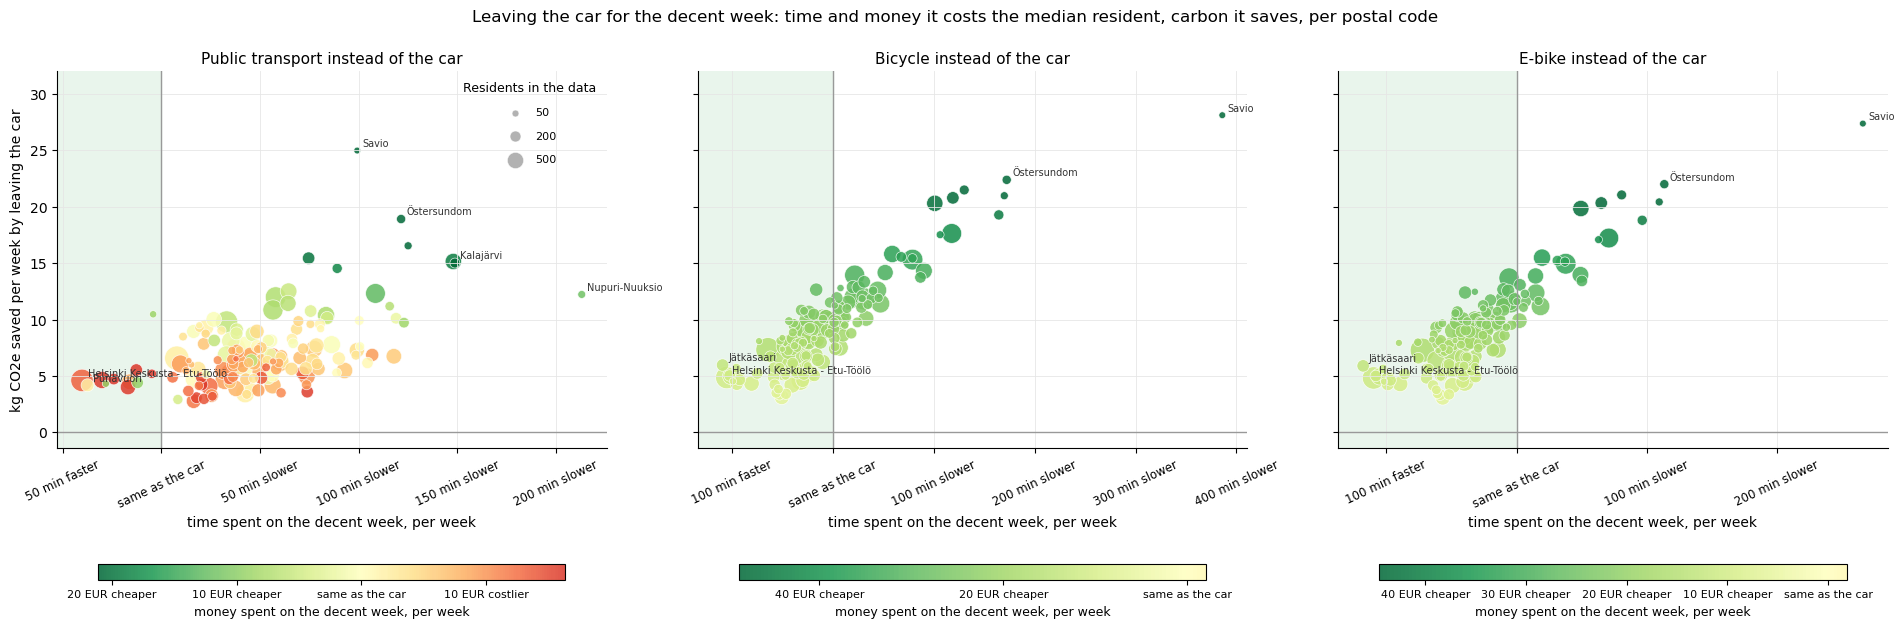

In [30]:
def worded(unit, less, more):
    '''Tick formatter that spells the sign out: "50 min faster", "same as the car", "100 min slower".'''
    def fmt(value, _position=None):
        if abs(value) < 1e-9:
            return "same as the car"
        return f"{abs(value):g} {unit} {less if value < 0 else more}"
    return FuncFormatter(fmt)


MONEY_CMAP = "RdYlGn_r"   # cheaper than the car in green, costlier in red


def money_scale(values):
    '''Colormap and norm for money: the symmetric diverging scale (white at "same as the car"),
    cut to the range of values present so the bar stays linear and the colours readable.'''
    low, high = np.nanpercentile(values, [2, 98])
    span = max(high - low, 1.0)
    low, high = min(low, -0.05 * span), max(high, 0.05 * span)
    limit = max(abs(low), abs(high))
    full = plt.get_cmap(MONEY_CMAP)
    cut = ListedColormap(full(np.linspace((low + limit) / (2 * limit), (high + limit) / (2 * limit), 256)))
    return cut, Normalize(low, high)


figure, axes = plt.subplots(ncols=len(ALTERNATIVES), figsize=(6.4 * len(ALTERNATIVES), 6.6), sharey=True)
for axis, alt in zip(axes, ALTERNATIVES):
    points = advantage_points(alt).sort_values("n_users", ascending=False)   # small bubbles drawn on top
    money_cmap, money_norm = money_scale(points["extra_euros"])
    bubbles = axis.scatter(
        points["extra_minutes"], points["saved_kg"], s=bubble_area(points["n_users"]),
        c=points["extra_euros"], cmap=money_cmap, norm=money_norm,
        alpha=0.85, edgecolor="white", linewidth=0.5,
    )
    left, right = axis.get_xlim()
    left, right = min(left, -0.05 * (right - left)), max(right, 0.05 * (right - left))
    axis.axvspan(left, 0, color=FASTER_SHADE, zorder=0)
    axis.set_xlim(left, right)
    axis.axvline(0, color="#999999", linewidth=1)
    axis.axhline(0, color="#999999", linewidth=1)
    axis.xaxis.set_major_locator(MaxNLocator(nbins=8, steps=[1, 2, 5, 10]))
    axis.xaxis.set_major_formatter(worded("min", "faster", "slower"))
    axis.tick_params(axis="x", labelrotation=25, labelsize=8.5)
    extremes = pd.concat([
        points.nlargest(N_LABELLED, "extra_minutes"), points.nsmallest(N_LABELLED, "extra_minutes"),
        points.nlargest(N_LABELLED, "saved_kg"),
    ]).drop_duplicates()
    for _, p in extremes.iterrows():
        axis.annotate(p["Nimi"], (p["extra_minutes"], p["saved_kg"]), fontsize=7, xytext=(4, 3), textcoords="offset points", color="#333333")
    axis.set_title(f"{MODE_LABELS[alt]} instead of the car", fontsize=11)
    axis.set_xlabel("time spent on the decent week, per week")
    axis.grid(color="#e6e6e6", linewidth=0.6)
    axis.spines[["top", "right"]].set_visible(False)
    bar = figure.colorbar(bubbles, ax=axis, orientation="horizontal", shrink=0.85, pad=0.2, aspect=30)
    bar.set_label("money spent on the decent week, per week", fontsize=9)
    bar.ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    bar.ax.xaxis.set_major_formatter(worded("EUR", "cheaper", "costlier"))
    bar.ax.tick_params(labelsize=8)
axes[0].set_ylabel("kg CO2e saved per week by leaving the car")
bottom, top = axes[0].get_ylim()
axes[0].set_ylim(bottom, top + 0.08 * (top - bottom))

size_handles = [
    axes[0].scatter([], [], s=bubble_area(n), color="#999999", alpha=0.75, edgecolor="white", linewidth=0.5, label=f"{n}")
    for n in SIZE_LEGEND_RESIDENTS
]
axes[0].legend(handles=size_handles, frameon=False, title="Residents in the data", loc="upper right", labelspacing=1.2, fontsize=8, title_fontsize=9)
figure.suptitle("Leaving the car for the decent week: time and money it costs the median resident, carbon it saves, per postal code", y=0.995)
figure.tight_layout()
figure.savefig(RESULTS / "scatter_against_carbon.png", dpi=150)


### Price of carbon, best and worst postal codes

Median extra minutes (top row) and extra euros (bottom row) per week per kg CO₂e
saved when public transport, the bicycle or the e-bike (one column each) replaces the car for the
decent week. The bar spans the interquartile range across residents. Negative
values mean the alternative is both cheaper in that currency and cleaner for the
median resident.

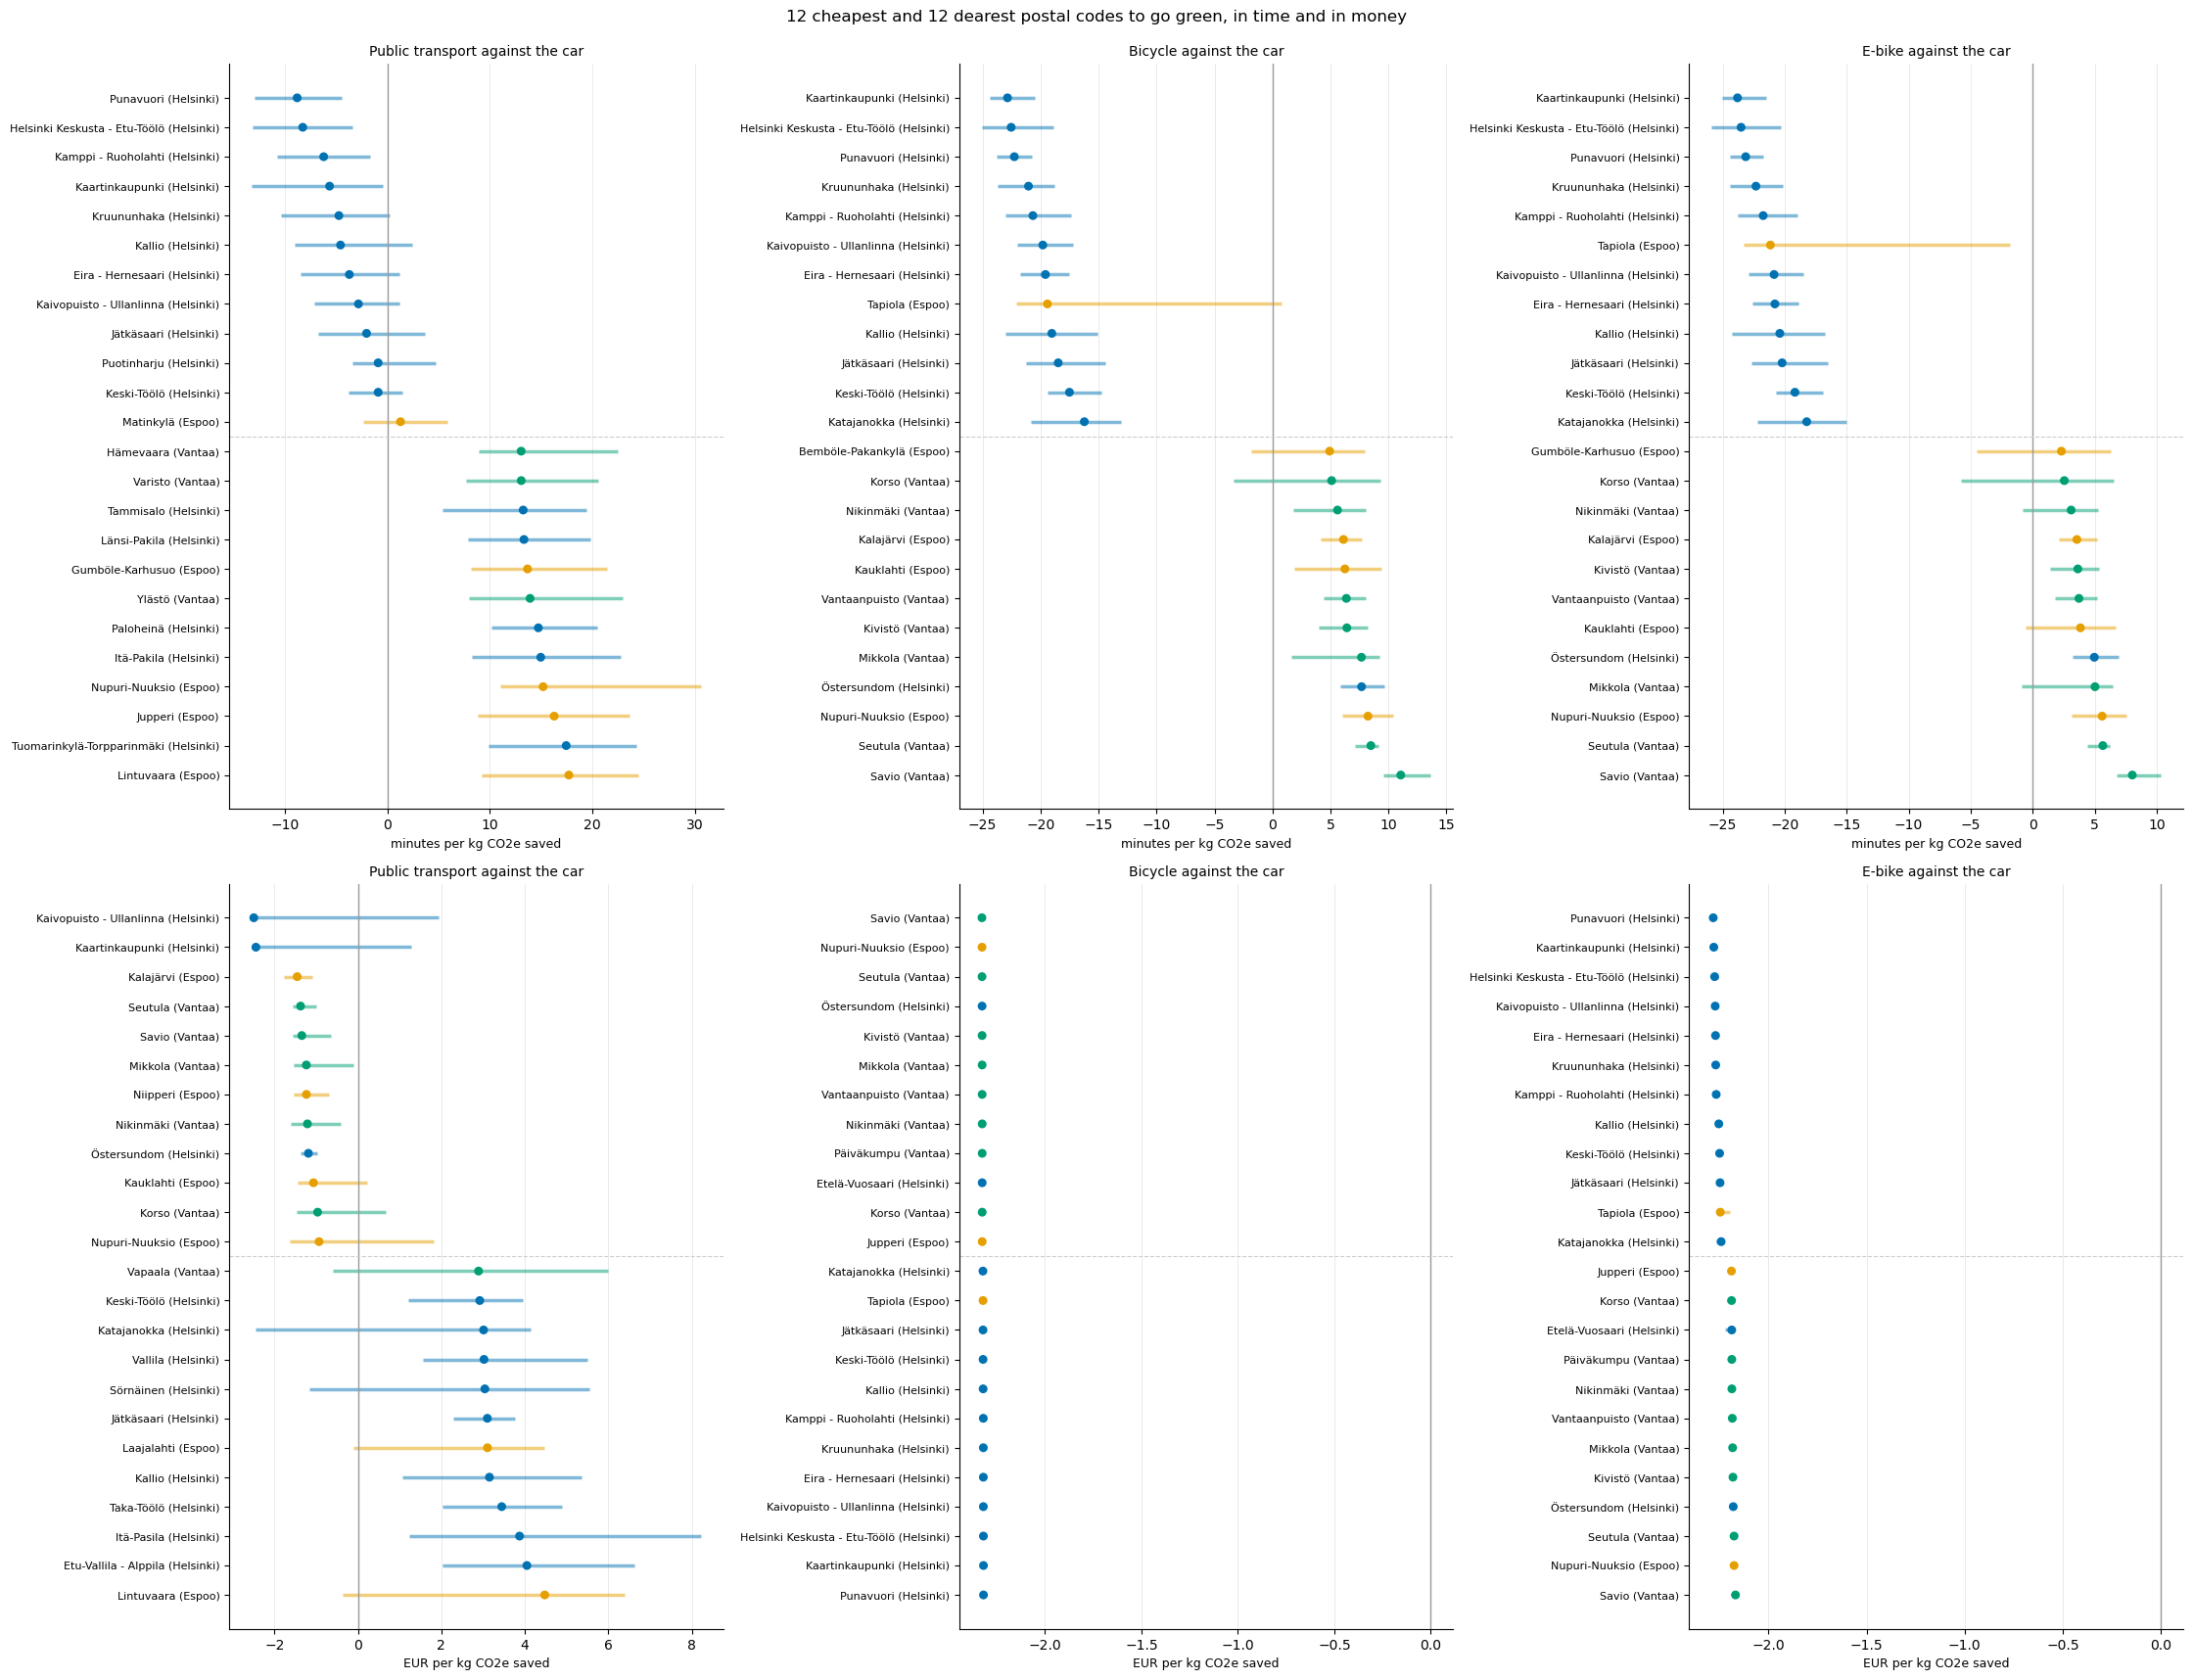

In [31]:
N_SHOWN = 12


def draw_ranking(axis, rows, xlabel, title):
    '''Dot-and-range chart of the cheapest and dearest postal codes for one price.'''
    ends = pd.concat([rows.head(N_SHOWN), rows.tail(N_SHOWN)]).reset_index(drop=True)
    position = np.arange(len(ends))
    colours = ends["Kunta"].map(KUNTA_COLOURS)
    axis.hlines(position, ends["p25"], ends["p75"], color=colours, linewidth=2.5, alpha=0.5)
    axis.scatter(ends["median"], position, color=colours, s=30, zorder=3)
    axis.axvline(0, color="#999999", linewidth=1)
    axis.axhline(N_SHOWN - 0.5, color="#cccccc", linewidth=0.8, linestyle="--")
    axis.set_yticks(position)
    axis.set_yticklabels([f"{n} ({k})" for n, k in zip(ends["Nimi"], ends["Kunta"])], fontsize=8)
    axis.invert_yaxis()
    axis.set_xlabel(xlabel, fontsize=9)
    axis.set_title(title, fontsize=10)
    axis.grid(axis="x", color="#e6e6e6", linewidth=0.6)
    axis.spines[["top", "right"]].set_visible(False)


figure, axes = plt.subplots(
    nrows=len(PRICE_CURRENCIES), ncols=len(ALTERNATIVES),
    figsize=(7.5 * len(ALTERNATIVES), (0.3 * 2 * N_SHOWN + 1.4) * len(PRICE_CURRENCIES)),
)
for row, currency in zip(axes, PRICE_CURRENCIES):
    for axis, alt in zip(row, ALTERNATIVES):
        rows = price_by_postal_code.loc[
            (price_by_postal_code["alternative"] == alt) & (price_by_postal_code["currency"] == currency)
            & price_by_postal_code["enough_users"]
        ].sort_values("median")
        draw_ranking(axis, rows, PRICE_UNITS[currency], f"{MODE_LABELS[alt]} against the car")
figure.suptitle(f"{N_SHOWN} cheapest and {N_SHOWN} dearest postal codes to go green, in time and in money", y=0.995)
figure.tight_layout()
figure.savefig(RESULTS / "ranking_price_of_carbon.png", dpi=150)

### Where each mode competes, by category

Median across residents of the log₂ ratio of the alternative's near-trip time to the
car's, per category. Blue: the alternative is faster than the car; red: slower.

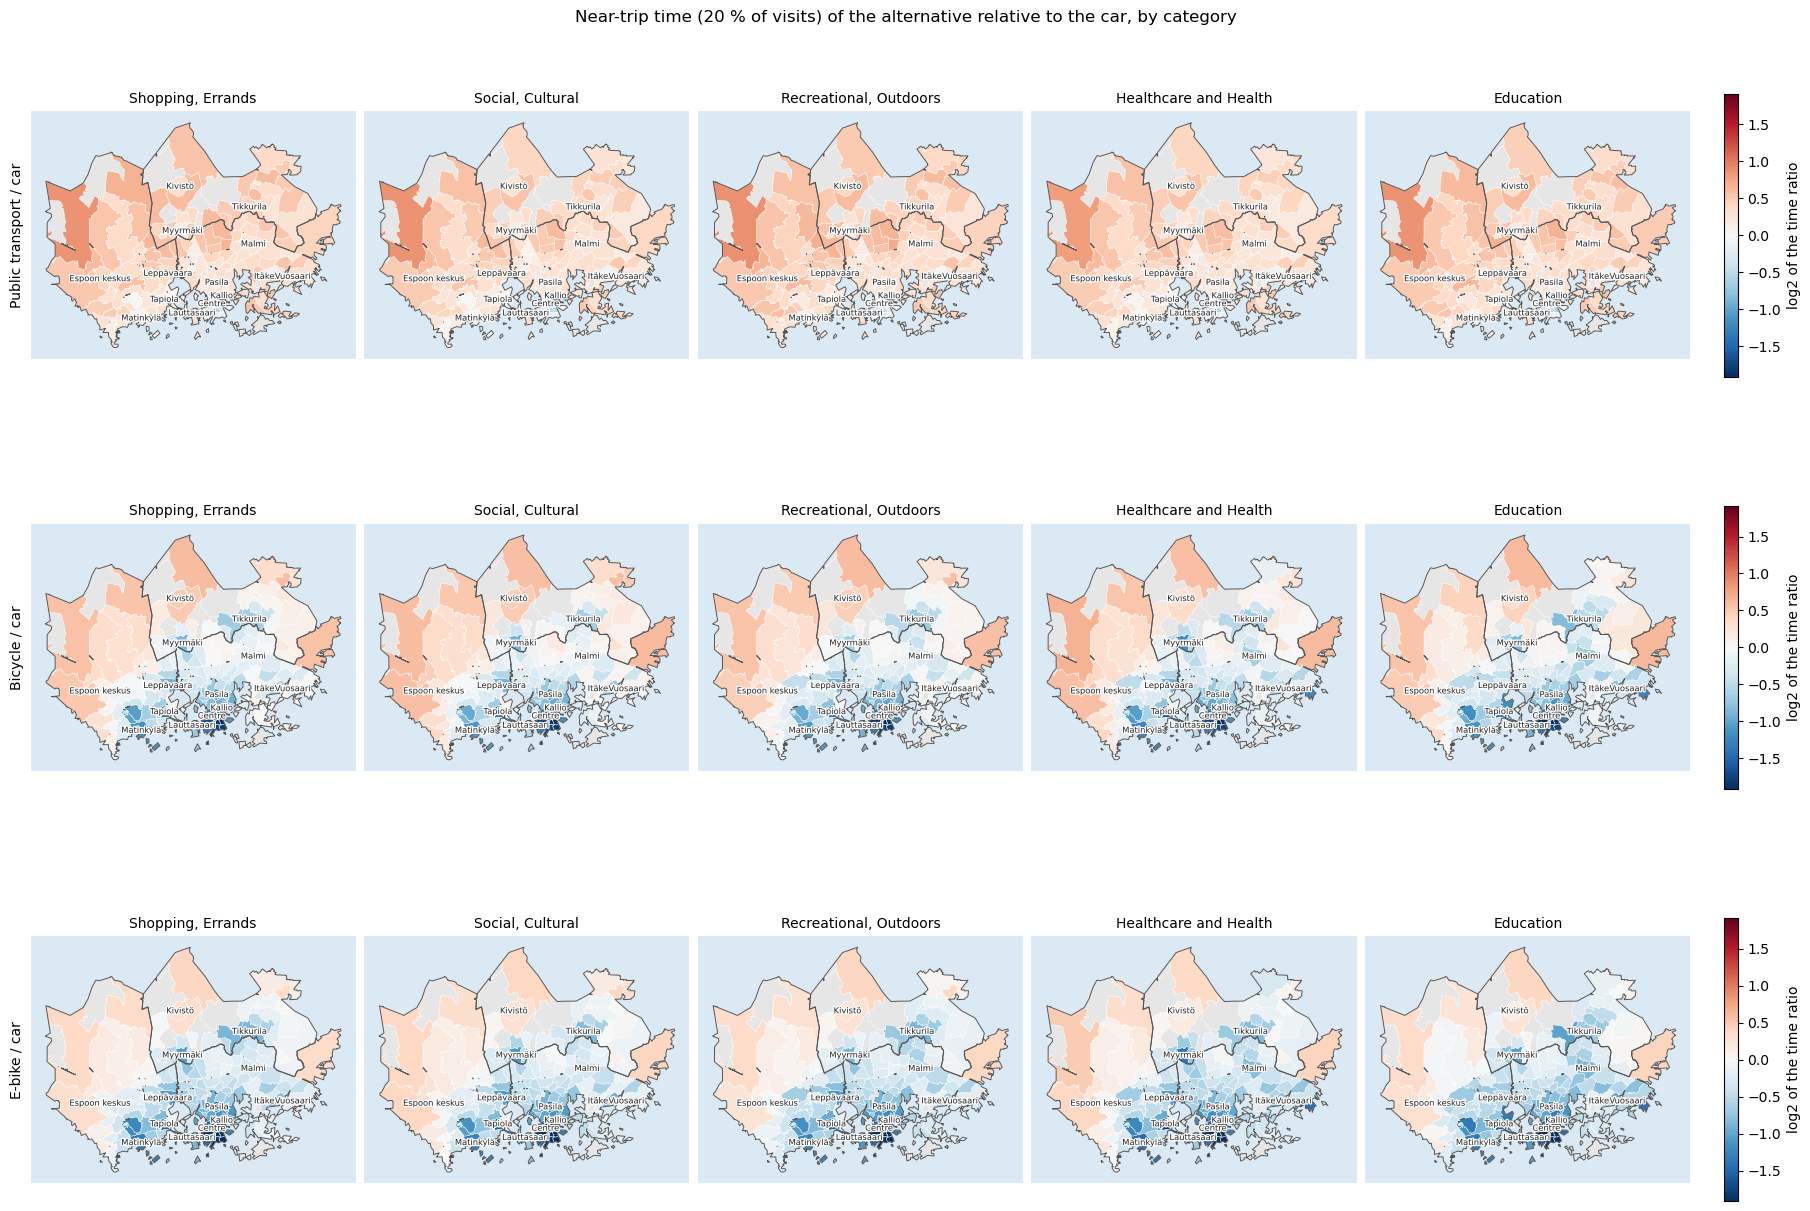

In [32]:
figure, axes = plt.subplots(
    nrows=len(ALTERNATIVES), ncols=len(CATEGORIES),
    figsize=(3.6 * len(CATEGORIES), 4.2 * len(ALTERNATIVES)), constrained_layout=True,
)
ratios = by_category.loc[
    (by_category["currency"] == "time_min") & by_category["metric"].str.startswith("log2_") & by_category["enough_users"],
    "median",
]
limit = np.nanpercentile(ratios.abs(), 98)
for row, alt in zip(axes, ALTERNATIVES):
    metric = f"log2_{alt}_over_{REFERENCE_MODE}"
    for axis, category in zip(row, CATEGORIES):
        values = values_for(by_category, currency="time_min", metric=metric, poi_type=category)
        draw(axis, values, DIVERGING, -limit, limit)
        axis.set_title(category, fontsize=10)
    row[0].text(-0.02, 0.5, f"{MODE_LABELS[alt]} / car", transform=row[0].transAxes,
                rotation=90, va="center", ha="right", fontsize=10)
    colourbar(figure, row, DIVERGING, -limit, limit, "log2 of the time ratio")
figure.suptitle(f"Near-trip time ({THRESHOLD} % of visits) of the alternative relative to the car, by category")
figure.savefig(RESULTS / "map_time_ratio_by_category.png", dpi=150)

## Caveats

- Time and CO₂ come from notebook `02.5`, where each mode's curve uses the stays
  that have a cost in that mode's matrix. The matrices cut off long trips (3,000 g
  for public transport and bicycle, 6,000 g for the car), so the stay sets differ
  slightly between modes. The low threshold limits the effect, since the missing
  pairs are the far ones, but the share denominator still shrinks for users with
  many long trips.
- Transit money is priced on the `02.1` lattice at resolution 8, so a stay takes the
  fare of its parent cell; pairs outside the lattice have no fare and are left out
  of the money curve. The fare is the HSL single ticket per leg, as in `02.4`; a
  season ticket would make the weekly cost a flat amount per zone and lower it for
  regular users. Transit time comes from the paper's matrix and transit money from
  cafein's, two routers that may choose different itineraries for the same pair.
- Car money is the driven distance of the `02.5` curve at 0.36 EUR per kilometre,
  a running cost without ownership; bicycle and e-bike money are the `02.1` bicycle
  running cost in EUR2017, as `02.4` uses it.
- The weekly routine is a normative assumption from the carbon-budget paper, not an
  observed frequency, and it leaves out the commute that the paper counted four
  times per week. Weekly figures are therefore not comparable with the paper's
  budgets without adding the commute. `WEEKLY_VISITS` is the single place to change
  the routine, including giving healthcare and education a weight.
- A resident's near trip is one point of the curve, the cost at which the first
  `THRESHOLD` percent of visits are reached; residents whose visits are
  concentrated in one far place have a near trip as far as that place.
- Bicycle and e-bike times are derived from the same slope-weighted distances at one
  assumed speed each, and the e-bike's CO₂ is one life-cycle factor (`02.5`);
  car and public transport times are the matrix times; all costs inherit the
  conventions of the paper's matrices.
- Postal codes below the minimum number of residents are kept in the tables with
  `enough_users = False` and are grey on the maps.